# DCCubos · Clasificación de piezas LEGO
**IIC2613 — Inteligencia Artificial · Tarea 1 · 2026-2**

**Pregunta:** ¿conviene reconocer una pieza por su imagen, por su ficha técnica o combinando ambas?

Este notebook desarrolla los tres tracks con modelos clásicos, sin deep learning. Parte de la plantilla del profesor, conservada en el repositorio. Cada decisión se explica antes de ejecutarse y las interpretaciones se apoyan en salidas verificables.

**Autor/a:** completar antes de entregar. **Uso de IA:** se utilizó Codex para planificar, generar y revisar código y explicaciones. El estudiante debe revisar y adaptar las explicaciones a sus ejecuciones y adjuntar los prompts y respuestas relevantes (ver `ANEXO_IA.md`). Esto es una declaración de asistencia, no de resultados ya obtenidos.

## Cómo ejecutarlo en Colab
1. Sube este notebook y `piezas_dataset.csv`. Ejecuta las celdas en orden con **Entorno de ejecución → Ejecutar todas**.
2. Usa un entorno **CPU**: estas implementaciones de scikit-learn no usan automáticamente la GPU de Colab.
3. La primera descarga de Kaggle ocupa aproximadamente 1 GB según el enunciado. Si solicita autenticación, ejecuta `import kagglehub; kagglehub.login()` en otra celda y repite la carga. No escribas tokens en el notebook.
4. Revisa las máscaras, las tablas y las matrices de confusión. El bloque final genera un borrador PDF, tablas, figuras y un ZIP de resultados.
5. Descarga también **este notebook ejecutado** desde Archivo → Descargar → .ipynb. El ZIP de resultados no puede capturar automáticamente el estado del notebook abierto en Colab.

**Entrega académica:** notebook ejecutado, CSV original y `respuesta.pdf` revisado. No incluir las imágenes ni `data/`. Los textos que solicitan interpretación propia son parte del trabajo del estudiante.

## Recorrido
1. Configuración y protocolo experimental.
2. Carga y cruce de fuentes; reserva del conjunto de prueba.
3. Track A: máscaras, descriptores y validación de 12 configuraciones.
4. Track B: auditoría, limpieza y validación de las mismas configuraciones.
5. Track C: selección de características dentro de cada fold y combinación.
6. Ranking por validación, evaluación final, experimento con category y análisis de errores.
7. Exportación y guía de respuestas.


## 1. Entorno y reproducibilidad

Instalamos versiones dentro de intervalos compatibles, sin forzar una reinstalación del entorno base de Colab. Guardamos las versiones exactas realmente utilizadas. Para repetir la ejecución en otro momento se puede usar el archivo `versiones_reproducibles.txt` exportado. Si Colab avisa de que una biblioteca ya importada cambió, reinicia el entorno y comienza de nuevo.

Las dependencias de desarrollo (`nbformat`, `nbclient`) solo se necesitan para validar el notebook desde el repositorio, no en Colab.


In [1]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<4" "scipy>=1.11,<2" "scikit-learn>=1.5,<2" "scikit-image>=0.24,<0.27" "matplotlib>=3.8,<4" "pillow>=10,<13" "kagglehub>=0.3,<2" "reportlab>=4,<6" "tqdm>=4.66,<5"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.4 MB/s eta 0:00:00


In [2]:
import hashlib
import importlib.metadata
import json
import math
import platform
import time
import warnings
import zipfile
from datetime import datetime
from pathlib import Path
from xml.sax.saxutils import escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, FileLink
from tqdm.auto import tqdm
from skimage.filters import threshold_otsu
from skimage.morphology import closing, disk
from skimage.measure import label as connected_components, regionprops
from skimage.feature import hog
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits
from scipy.special import fdtrc

TABULAR_COLUMNS = ['weight_g', 'height_mm', 'n_studs', 'footprint_mm2', 'price']
GEOMETRY_COLUMNS = ['area_fraction', 'aspect_ratio', 'solidity', 'eccentricity', 'extent', 'circularity']
MODEL_NAMES = ['SVM', 'RandomForest', 'DecisionTree', 'KNN']


In [3]:
SEED = 42
N_SPLITS = 5
N_JOBS = 2  # Dos folds en paralelo; evita saturar RAM o multiplicar hilos.
DATASET_HANDLE = 'joosthazelzet/lego-brick-images'
LOCAL_IMAGES = None  # Opcional: ruta a imágenes ya descargadas, p. ej. '/content/dataset'.
BASE_DIR = Path.cwd()
if not (BASE_DIR / 'piezas_dataset.csv').exists() and (BASE_DIR / '01 - DCCubos/piezas_dataset.csv').exists():
    BASE_DIR = BASE_DIR / '01 - DCCubos'
CSV_PATH = BASE_DIR / 'piezas_dataset.csv'
RUN_ID = datetime.now().strftime('%Y%m%d-%H%M%S-%f')
# Una carpeta nueva por ejecución evita mezclar métricas o figuras antiguas.
RESULTS = BASE_DIR / 'resultados' / RUN_ID
FIGURES = RESULTS / 'figuras'
CACHE = BASE_DIR / 'cache'
for folder in (RESULTS, FIGURES, CACHE):
    folder.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'scikit-image', 'matplotlib', 'pillow', 'kagglehub', 'reportlab']
versions = {name: importlib.metadata.version(name) for name in packages}
(RESULTS / 'versiones_reproducibles.txt').write_text('\n'.join(f'{k}=={v}' for k, v in versions.items()), encoding='utf-8')
print('Python:', platform.python_version(), '| salida:', RESULTS)
display(pd.Series(versions, name='versión').to_frame())


Python: 3.13.15 | salida: /content/resultados/20261001-184851-563077


,versión
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
scikit-image,0.25.2
matplotlib,3.10.0
pillow,11.3.0
kagglehub,1.0.2
reportlab,5.0.1


### Protocolo fijado antes de comparar resultados

- **80/20 estratificado:** normalmente 1.920 observaciones para entrenar y 480 para evaluar, con las ocho clases representadas. Ordenamos por `filename` antes de dividir para que el orden del CSV no cambie la partición.
- **Cinco folds:** la selección se hace únicamente dentro del 80% de entrenamiento, con los mismos folds para A/B/C. Cada imputador, escalador y selector se ajusta de nuevo dentro de cada fold.
- **Duplicados visuales:** calculamos el hash de los píxeles que recibe el extractor. Si hay copias exactas, mantenemos el grupo completo en un solo lado de la partición y en un solo fold. En ese caso el 80/20 es aproximado; la tabla mostrará los tamaños efectivos. No cubre todas las vistas casi idénticas.
- **Accuracy** es la métrica de selección pedida. Añadimos F1 macro, desviación entre folds y tiempos para interpretar mejor los resultados. La desviación de cinco folds no es un intervalo de confianza.
- **12 configuraciones fijas por track:** SVM, Random Forest, árbol y KNN, tres cada uno. Los empates se resuelven por menor desviación de validación y después por un identificador estable, nunca por test.
- El ranking y los ganadores de cada modelo se fijan **antes** de mirar el test. No se cambiarán parámetros después de ver sus errores.

Hay selección entre 36 candidatos: la puntuación del ganador en validación puede ser optimista. El test estima el desempeño final; no certifica generalización a fotos reales, iluminación diferente o nuevas familias de piezas.

Fuente metodológica: [scikit-learn, errores comunes y prevención de leakage](https://scikit-learn.org/stable/common_pitfalls.html).


## 2. Cargar las fuentes y comprobar su correspondencia

`filename` es una llave, no una característica: contiene el nombre de la clase. `label` es el objetivo. El cruce exige correspondencia uno a uno y etiquetas consistentes. Si falta una imagen, fallamos con un diagnóstico en lugar de eliminar filas silenciosamente y comparar poblaciones diferentes.

Leemos directamente desde la caché de Kaggle: evitamos copiar 1 GB y borrar carpetas al repetir una celda. El manifiesto identifica las ocho clases que realmente necesitamos.


In [4]:
def align_sources(manifest, inventory):
    if manifest.filename.duplicated().any() or inventory.filename.duplicated().any():
        raise ValueError('filename debe ser único en ambas fuentes.')
    joined = manifest.merge(inventory, on='filename', how='left', validate='one_to_one',
                            suffixes=('', '_inventory'), indicator=True, sort=False)
    if not joined['_merge'].eq('both').all():
        raise ValueError('Hay imágenes sin ficha técnica.')
    if 'label_inventory' in joined and not joined['label'].eq(joined['label_inventory']).all():
        raise ValueError('Las etiquetas de imagen y ficha no coinciden.')
    return joined.drop(columns=['_merge', 'label_inventory'], errors='ignore')


def load_gray(path):
    with Image.open(path) as image:
        return np.asarray(image.convert('L').resize((128, 128), Image.Resampling.BILINEAR), dtype=np.uint8)


def find_required_images(root, filenames):
    required = set(filenames)
    found = {}
    for path in Path(root).rglob('*'):
        if path.is_file() and path.name in required:
            if path.name in found:
                raise ValueError(f'Nombre ambiguo en la descarga: {path.name}. Usa LOCAL_IMAGES con una sola carpeta dataset.')
            found[path.name] = str(path)
    missing = sorted(required - set(found))
    if missing:
        raise FileNotFoundError(f'Faltan {len(missing)} imágenes. Ejemplos: {missing[:5]}')
    return found


In [5]:
if not CSV_PATH.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Coloca piezas_dataset.csv junto al notebook.') from exc
    print('Selecciona el CSV proporcionado por el profesor:')
    files.upload()
    if not CSV_PATH.exists():
        raise FileNotFoundError('No se encontró piezas_dataset.csv tras la subida.')

inventory_raw = pd.read_csv(CSV_PATH)
required_columns = {'filename', 'label', *TABULAR_COLUMNS, 'year_released', 'category', 'finish', 'is_defective'}
if not required_columns.issubset(inventory_raw.columns):
    raise ValueError(f'Faltan columnas: {required_columns - set(inventory_raw.columns)}')
if inventory_raw[['filename', 'label']].isna().any().any():
    raise ValueError('El manifiesto contiene identificadores o etiquetas vacíos.')
if inventory_raw.filename.duplicated().any():
    raise ValueError('El CSV contiene nombres de archivo duplicados.')
if inventory_raw.label.nunique() != 8:
    raise ValueError('Se esperaban las ocho clases del enunciado.')

if LOCAL_IMAGES is None:
    import kagglehub
    downloaded = Path(kagglehub.dataset_download(DATASET_HANDLE))
    images_root = downloaded / 'dataset' if (downloaded / 'dataset').is_dir() else downloaded
else:
    images_root = Path(LOCAL_IMAGES)
image_index = find_required_images(images_root, inventory_raw.filename)
manifest = inventory_raw[['filename', 'label']].sort_values('filename').reset_index(drop=True)
manifest['path'] = manifest.filename.map(image_index)
manifest['image_hash'] = [hashlib.sha256(load_gray(p).tobytes()).hexdigest()
                          for p in tqdm(manifest.path, desc='Verificar píxeles')]
if manifest.groupby('image_hash').label.nunique().gt(1).any():
    raise ValueError('Hay imágenes idénticas con etiquetas incompatibles. Revisa la fuente antes de entrenar.')
dataset = align_sources(manifest, inventory_raw)
labels = sorted(dataset.label.unique())
short_labels = [name.split()[0] for name in labels]
display(dataset.groupby('label').size().rename('ejemplos').to_frame())
print('Correspondencias verificadas:', len(dataset), '| copias visuales adicionales:', dataset.image_hash.duplicated().sum())


Using Colab cache for faster access to the 'lego-brick-images' dataset.


Verificar píxeles:   0%|          | 0/2400 [00:00<?, ?it/s]

,ejemplos
label,
3001 brick 2x4,300
3003 brick 2x2,300
3004 brick 1x2,300
3005 brick 1x1,300
3022 Plate 2x2,300
3040 roof tile 1x2,300
3062 Round Brick 1x1,300
3069 Flat Tile 1x2,300


Correspondencias verificadas: 2400 | copias visuales adicionales: 0


In [6]:
def make_partition(data, seed=42):
    ordered = data.sort_values('filename').reset_index(drop=True)
    groups = ordered['image_hash'] if 'image_hash' in ordered else ordered['filename']
    if groups.duplicated().any():
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        train_idx, test_idx = next(splitter.split(ordered, ordered.label, groups))
    else:
        train_idx, test_idx = train_test_split(np.arange(len(ordered)), test_size=.20,
                                               stratify=ordered.label, random_state=seed)
    partition = ordered[['filename', 'label']].copy()
    partition['split'] = 'train'
    partition.loc[test_idx, 'split'] = 'test'
    assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
    if partition.groupby('label')['split'].nunique().ne(2).any():
        raise ValueError('Alguna clase no aparece en ambos conjuntos.')
    return partition


split,test,train
label,,
3001 brick 2x4,60,240
3003 brick 2x2,60,240
3004 brick 1x2,60,240
3005 brick 1x1,60,240
3022 Plate 2x2,60,240
3040 roof tile 1x2,60,240
3062 Round Brick 1x1,60,240
3069 Flat Tile 1x2,60,240


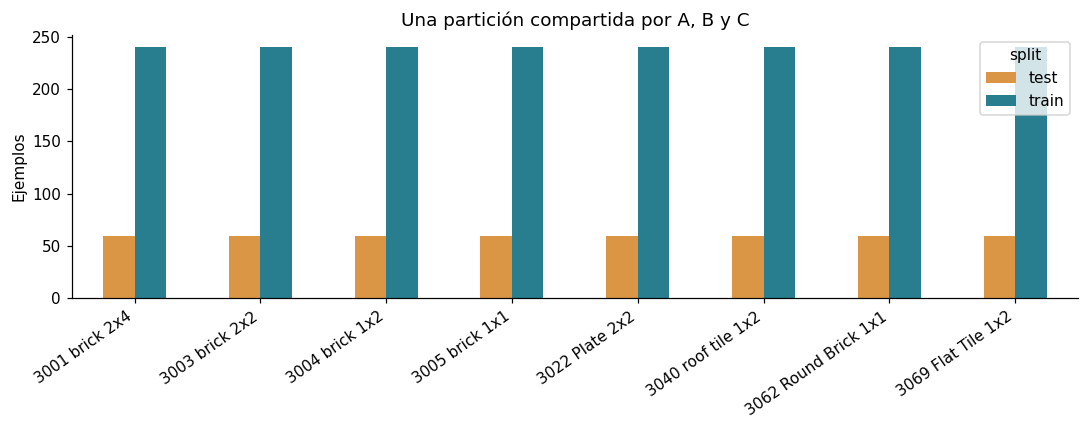

In [7]:
partition = make_partition(dataset, seed=SEED)
partition.to_csv(RESULTS / 'particion.csv', index=False)
dataset = dataset.set_index('filename').loc[partition.filename].reset_index()
train_idx = np.flatnonzero(partition.split.eq('train'))
test_idx = np.flatnonzero(partition.split.eq('test'))
train_data = dataset.iloc[train_idx].reset_index(drop=True)
y_train = train_data.label.copy()
groups_train = train_data.image_hash
if groups_train.duplicated().any():
    cv_splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    CV_SPLITS = list(cv_splitter.split(train_data, y_train, groups_train))
else:
    cv_splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    CV_SPLITS = list(cv_splitter.split(train_data, y_train))
fold_assignments = []
for fold, (fit_idx, valid_idx) in enumerate(CV_SPLITS, start=1):
    assert set(groups_train.iloc[fit_idx]).isdisjoint(set(groups_train.iloc[valid_idx]))
    assert set(y_train.iloc[valid_idx]) == set(labels)
    fold_assignments.extend({'filename': name, 'validation_fold': fold} for name in train_data.filename.iloc[valid_idx])
pd.DataFrame(fold_assignments).to_csv(RESULTS / 'folds.csv', index=False)
split_counts = partition.groupby(['label', 'split']).size().unstack()
display(split_counts)
fig, ax = plt.subplots(figsize=(10, 4))
split_counts.plot.bar(ax=ax, color=['#da9645', '#287d8e'])
ax.set(ylabel='Ejemplos', title='Una partición compartida por A, B y C', xlabel='')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
fig.savefig(FIGURES / '01_particion.png')
plt.show()


## 3. Track A · Qué información extraemos de las imágenes

**Hipótesis, no resultado:** las dimensiones aparentes pueden distinguir ladrillos largos, cuadrados y placas; contornos y gradientes internos pueden separar una pieza inclinada, una redonda y una loseta sin studs.

Usamos **HOG** (9 orientaciones, celdas de 16×16 y bloques de 2×2): resume direcciones de bordes tanto interiores como del contorno. En 128×128 genera 1.764 números. Es una resolución moderada para CPU; no suponemos invariancia completa a rotaciones. [Dalal y Triggs, 2005, explicación e implementación oficial](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html).

La máscara usa la referencia del profesor: diferencia con el fondo estimado en el borde, umbral Otsu y cierre morfológico. Conservamos el componente conectado mayor, suponiendo una pieza por imagen. Una máscara vacía o demasiado pequeña provoca un error. No inventamos un vector de ceros que el modelo podría aprender como si fuera una pieza.

Añadimos seis medidas geométricas, definidas sobre esa máscara:

| Medida | Qué representa | Limitación |
|---|---|---|
| Área relativa | Píxeles de pieza / píxeles totales | Depende de escala y perspectiva |
| Relación de lados | Anchura / altura de caja delimitadora | Cambia al rotar la pieza |
| Solidez | Área / área de envolvente convexa | Depende de calidad del contorno |
| Excentricidad | Alargamiento de la elipse equivalente | Formas diferentes pueden compartirla |
| Extensión | Área / área de caja delimitadora | Sensible a inclinación |
| Circularidad | 4π × área / perímetro de Crofton² | Discretización; no se fuerza artificialmente a [0,1] |

Fuente de todas las medidas y del perímetro: [documentación oficial de skimage.measure](https://scikit-image.org/docs/stable/api/skimage.measure.html). No añadimos Hu ni LBP por acumulación: el enunciado los sugiere, pero no obliga. Este conjunto permite una explicación concreta y combina forma global con estructura local.


In [8]:
def segment(image):
    border = np.concatenate([image[0], image[-1], image[:, 0], image[:, -1]])
    difference = np.abs(image.astype(float) - np.median(border))
    threshold = max(float(threshold_otsu(difference)), 10.)
    mask = closing(difference > threshold, disk(2))
    regions = regionprops(connected_components(mask))
    if not regions:
        raise ValueError('Máscara vacía: revisa el fondo y la segmentación.')
    largest = max(regions, key=lambda region: region.area)
    if largest.area < 50:
        raise ValueError('La máscara tiene menos de 50 píxeles; no representa una pieza fiable.')
    return connected_components(mask) == largest.label


def extract_image_features(image):
    mask = segment(image)
    region = regionprops(mask.astype(np.uint8))[0]
    min_row, min_col, max_row, max_col = region.bbox
    geometry = np.array([region.area / mask.size, (max_col - min_col) / (max_row - min_row),
                         region.solidity, region.eccentricity, region.extent,
                         4 * np.pi * region.area / max(region.perimeter_crofton ** 2, 1e-12)])
    descriptor = hog(image, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
                     block_norm='L2-Hys', feature_vector=True)
    features = np.r_[descriptor, geometry].astype(np.float32)
    if not np.isfinite(features).all():
        raise ValueError('El extractor produjo valores no finitos.')
    return features, mask


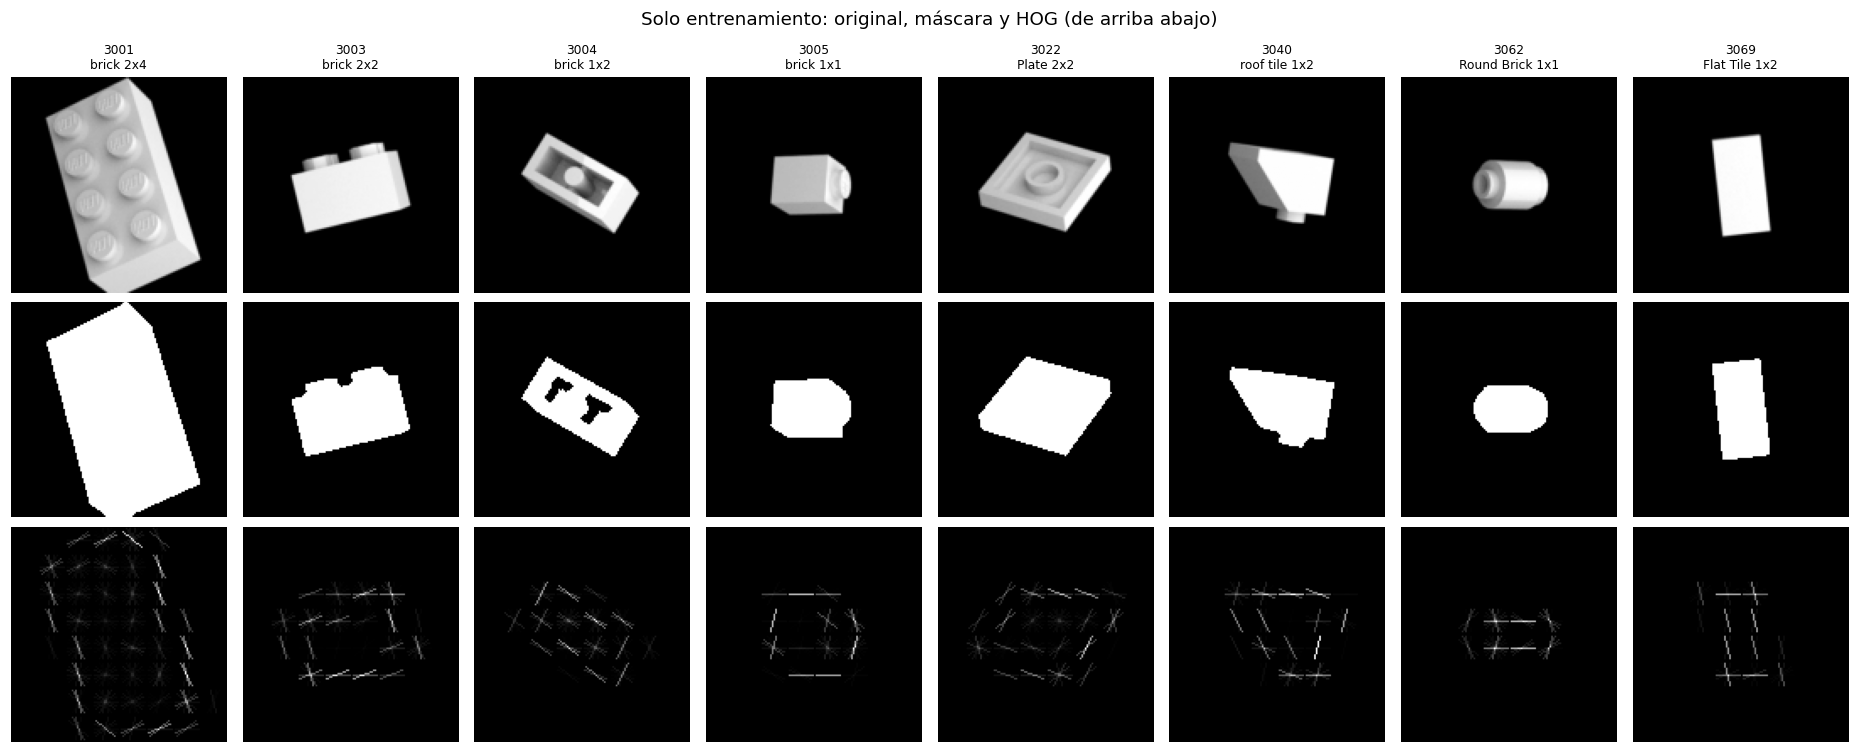

In [9]:
fig, axes = plt.subplots(3, len(labels), figsize=(17, 7))
for column, name in enumerate(labels):
    row = train_data[train_data.label.eq(name)].iloc[0]
    image = load_gray(row.path)
    _, mask = extract_image_features(image)
    _, hog_view = hog(image, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
                      block_norm='L2-Hys', visualize=True)
    for line, view in enumerate([image, mask, hog_view]):
        axes[line, column].imshow(view, cmap='gray')
        axes[line, column].axis('off')
    axes[0, column].set_title(name.replace(' ', '\n', 1), fontsize=8)
fig.suptitle('Solo entrenamiento: original, máscara y HOG (de arriba abajo)')
plt.tight_layout()
fig.savefig(FIGURES / '02_mascaras_hog.png')
plt.show()


### Extraer una vez, reutilizar sin leakage

HOG y las medidas geométricas se calculan por imagen sin aprender parámetros entre imágenes, de modo que pueden extraerse para todo el manifiesto. Todavía no inspeccionamos distribuciones ni resultados del test. El escalado y la selección supervisada sí se ajustarán dentro de cada fold.

La caché se identifica por los hashes de las imágenes, los parámetros y la versión de scikit-image. Si cambias el extractor, cambia `FEATURE_VERSION` para invalidarla. Las características se guardan en archivos NPZ sin objetos serializados.


HOG y geometría:   0%|          | 0/2400 [00:00<?, ?it/s]

Dimensiones: (2400, 1770)


,area_fraction,aspect_ratio,solidity,eccentricity,extent,circularity
label,,,,,,
3001 brick 2x4,0.363,1.199,0.956,0.845,0.602,0.680
3003 brick 2x2,0.210,1.025,0.955,0.536,0.676,0.772
3004 brick 1x2,0.133,1.073,0.951,0.720,0.644,0.774
3005 brick 1x1,0.083,1.022,0.951,0.530,0.693,0.815
3022 Plate 2x2,0.140,1.006,0.955,0.779,0.589,0.769
3040 roof tile 1x2,0.115,1.000,0.958,0.749,0.639,0.773
3062 Round Brick 1x1,0.062,0.945,0.949,0.754,0.696,0.833
3069 Flat Tile 1x2,0.075,1.100,0.959,0.868,0.593,0.728


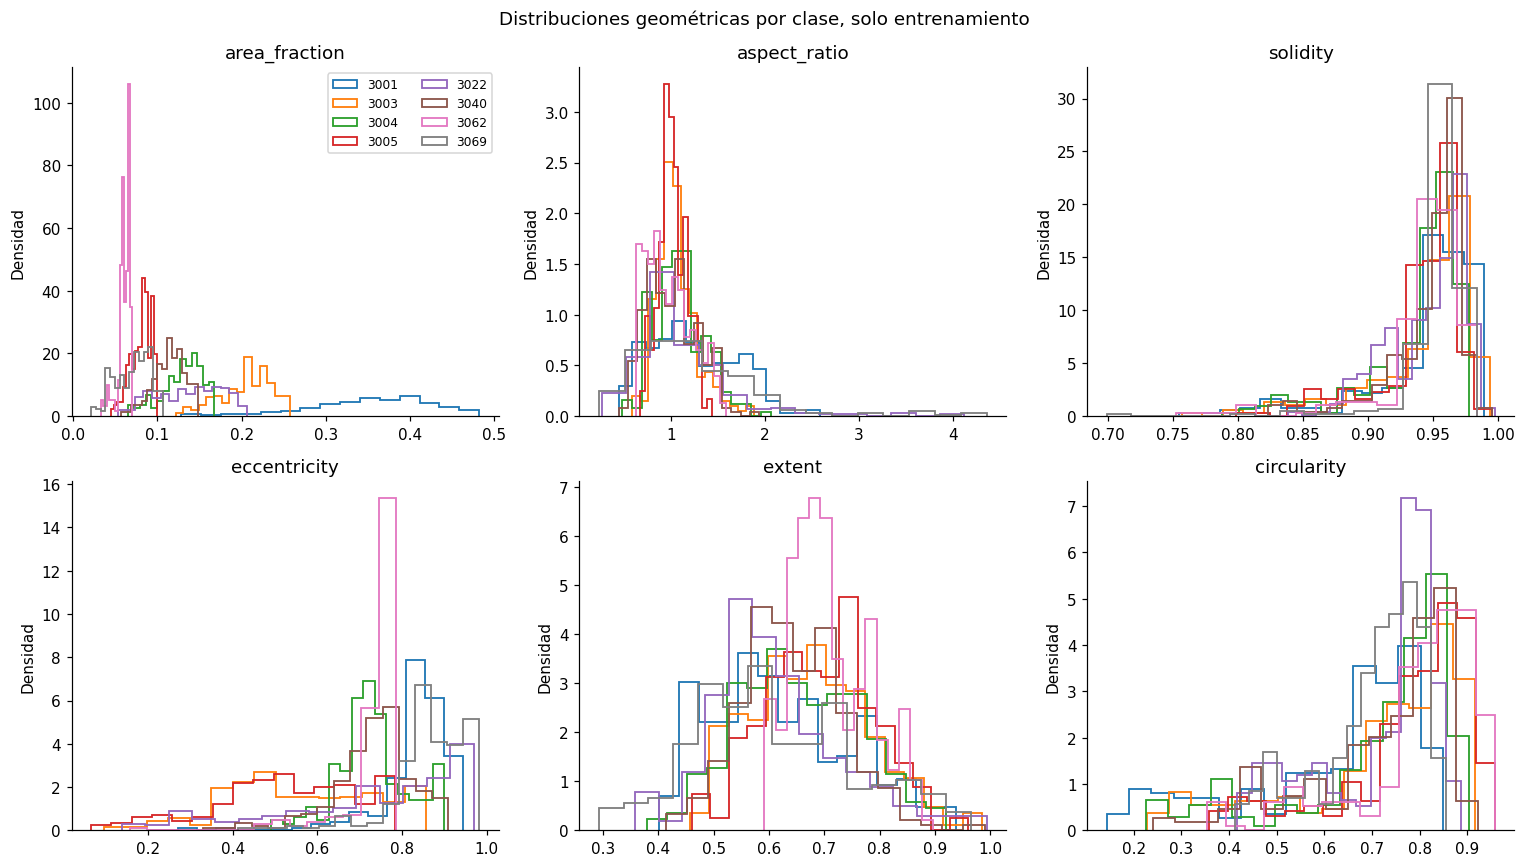

Máscaras con área extrema para revisión: 0


In [10]:
FEATURE_VERSION = 'hog16-geometry6-v1'
fingerprint = hashlib.sha256(json.dumps({'version': FEATURE_VERSION, 'skimage': versions['scikit-image'],
    'images': dataset[['filename', 'image_hash']].values.tolist()}, sort_keys=True).encode()).hexdigest()[:20]
feature_path = CACHE / f'features_{fingerprint}.npz'
if feature_path.exists():
    with np.load(feature_path, allow_pickle=False) as saved:
        if not np.array_equal(saved['filenames'], dataset.filename.to_numpy(dtype=str)):
            raise ValueError('La caché no coincide con el manifiesto.')
        feature_matrix = saved['features']
else:
    rows = []
    for row in tqdm(dataset.itertuples(index=False), total=len(dataset), desc='HOG y geometría'):
        try:
            features, _ = extract_image_features(load_gray(row.path))
        except ValueError as exc:
            raise ValueError(f'{row.filename}: {exc}') from exc
        rows.append(features)
    feature_matrix = np.vstack(rows)
    np.savez_compressed(feature_path, features=feature_matrix, filenames=dataset.filename.to_numpy(dtype=str))
visual_columns = [f'hog_{i:04d}' for i in range(feature_matrix.shape[1] - len(GEOMETRY_COLUMNS))] + GEOMETRY_COLUMNS
visual = pd.DataFrame(feature_matrix, columns=visual_columns, index=dataset.filename)
X_train_visual = visual.loc[train_data.filename].reset_index(drop=True)
assert np.isfinite(feature_matrix).all() and len(visual_columns) == 1770
print('Dimensiones:', visual.shape)
geometry_summary = X_train_visual[GEOMETRY_COLUMNS].copy()
geometry_summary['label'] = y_train
display(geometry_summary.groupby('label').median().round(3))
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for name, ax in zip(GEOMETRY_COLUMNS, axes.ravel()):
    for class_name in labels:
        ax.hist(geometry_summary.loc[y_train.eq(class_name), name], bins=15, histtype='step', density=True,
                label=class_name.split()[0], linewidth=1.2)
    ax.set(title=name, ylabel='Densidad')
axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle('Distribuciones geométricas por clase, solo entrenamiento')
plt.tight_layout()
fig.savefig(FIGURES / '03_geometria.png')
plt.show()
mask_audit = dataset[['filename', 'label']].copy()
mask_audit['area_fraction'] = feature_matrix[:, -6]
mask_audit['revisar'] = (mask_audit.area_fraction < .01) | (mask_audit.area_fraction > .90)
mask_audit.to_csv(RESULTS / 'auditoria_mascaras.csv', index=False)
print('Máscaras con área extrema para revisión:', int(mask_audit.revisar.sum()))


### Los cuatro modelos y las doce configuraciones

**SVM RBF:** puede separar fronteras no lineales; C controla cuánto se penalizan errores de entrenamiento y gamma el alcance de influencia de cada ejemplo. Variamos solo C para aislar su efecto.

**Random Forest:** combina árboles para reducir variabilidad; fijamos 200 árboles como compromiso previo entre promediado y coste y variamos profundidad (5, 15 y libre). **Árbol individual:** comparamos profundidades 3, 8 y libre para cubrir capacidad baja, intermedia y alta; la profundidad libre puede sobreajustar. Ambos usan `random_state` fijo. Estos valores no se presentan como óptimos universales: precisamente se evalúan con CV.

**KNN, cuarto modelo:** compara con vecinos cercanos. Usamos k=3, 7 y 15 para contrastar decisiones locales y progresivamente más suavizadas, siempre con ponderación por distancia. Es comprensible para vectores visuales y fichas numéricas; k pequeño puede ser sensible a ruido. En muchas dimensiones las distancias pueden discriminar peor y aumenta el coste de predicción. No suponemos que sea el ganador.

Escalamos las características visuales con `StandardScaler`, para que una coordenada no domine solo por sus unidades. En tabular usamos `RobustScaler` (mediana e IQR), por la presencia de extremos; no elimina los outliers. Los árboles casi no dependen de este reescalado monotónico, pero compartirlo permite mantener un pipeline común y reproducible.

Fuentes: [SVM](https://scikit-learn.org/stable/modules/svm.html), [bosques](https://scikit-learn.org/stable/modules/ensemble.html#forest), [árboles](https://scikit-learn.org/stable/modules/tree.html), [KNN](https://scikit-learn.org/stable/modules/neighbors.html), [preprocesamiento](https://scikit-learn.org/stable/modules/preprocessing.html).


In [11]:
CONFIGS = {
    'SVM': [{'C': value, 'kernel': 'rbf', 'gamma': 'scale'} for value in [.1, 1., 10.]],
    'RandomForest': [{'n_estimators': 200, 'max_depth': depth, 'min_samples_leaf': 1}
                     for depth in [5, 15, None]],
    'DecisionTree': [{'max_depth': depth, 'min_samples_leaf': 1} for depth in [3, 8, None]],
    'KNN': [{'n_neighbors': k, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
            for k in [3, 7, 15]],
}
config_table = pd.DataFrame([{'model': model, 'config': i, 'params': json.dumps(params, sort_keys=True)}
                              for model, choices in CONFIGS.items() for i, params in enumerate(choices, start=1)])
display(config_table)
config_table.to_csv(RESULTS / 'configuraciones.csv', index=False)


,model,config,params
0,SVM,1,"{""C"": 0.1, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
1,SVM,2,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
2,SVM,3,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
3,RandomForest,1,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
4,RandomForest,2,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es..."
5,RandomForest,3,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_..."
6,DecisionTree,1,"{""max_depth"": 3, ""min_samples_leaf"": 1}"
7,DecisionTree,2,"{""max_depth"": 8, ""min_samples_leaf"": 1}"
8,DecisionTree,3,"{""max_depth"": null, ""min_samples_leaf"": 1}"
9,KNN,1,"{""metric"": ""minkowski"", ""n_neighbors"": 3, ""p"":..."


In [12]:
def balance_block(values):
    # Evita que un bloque domine por tener muchas más coordenadas.
    return values / np.sqrt(max(values.shape[1], 1))


def safe_f_classif(values, target):
    # ANOVA de un factor, con casos degenerados explícitos para el fondo HOG.
    values = np.asarray(values, dtype=float)
    target = np.asarray(target)
    classes = np.unique(target)
    df_between, df_within = len(classes) - 1, len(values) - len(classes)
    if df_between <= 0 or df_within <= 0:
        raise ValueError('ANOVA necesita varias clases y grados de libertad residuales.')
    grand_mean = values.mean(axis=0)
    between = np.zeros(values.shape[1])
    within = np.zeros(values.shape[1])
    for class_name in classes:
        group = values[target == class_name]
        group_mean = group.mean(axis=0)
        between += len(group) * (group_mean - grand_mean) ** 2
        within += np.sum((group - group_mean) ** 2, axis=0)
    scores = np.zeros(values.shape[1])
    pvalues = np.ones(values.shape[1])
    regular = within > 0
    scores[regular] = (between[regular] / df_between) / (within[regular] / df_within)
    perfect = (within == 0) & (between > 0)
    scores[perfect] = np.finfo(float).max
    pvalues[regular] = fdtrc(df_between, df_within, scores[regular])
    pvalues[perfect] = 0.
    return scores, pvalues


def build_pipeline(track, model, params, visual_columns, seed=42):
    constructors = {'SVM': SVC, 'RandomForest': RandomForestClassifier,
                    'DecisionTree': DecisionTreeClassifier, 'KNN': KNeighborsClassifier}
    options = dict(params)
    if model in {'SVM', 'RandomForest', 'DecisionTree'}:
        options['random_state'] = seed
    if model in {'RandomForest', 'KNN'}:
        options['n_jobs'] = 1
    if model == 'SVM':
        options['cache_size'] = 256
    estimator = constructors[model](**options)
    branches = []
    if track in {'A', 'C'}:
        steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                 ('scaler', StandardScaler())]
        if track == 'C':
            steps += [('selector', SelectPercentile(score_func=safe_f_classif, percentile=25)),
                      ('balance', FunctionTransformer(balance_block, feature_names_out='one-to-one'))]
        branches.append(('visual', Pipeline(steps), visual_columns))
    if track in {'B', 'C', 'B_category', 'B_aux'}:
        numerical = TABULAR_COLUMNS + (['year_released'] if track == 'B_aux' else [])
        steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                 ('scaler', RobustScaler())]
        if track == 'C':
            steps.append(('balance', FunctionTransformer(balance_block, feature_names_out='one-to-one')))
        branches.append(('tabular', Pipeline(steps), numerical))
    if track in {'B_category', 'B_aux'}:
        categorical = ['category'] if track == 'B_category' else ['finish', 'is_defective']
        branches.append(('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical))
    if not branches:
        raise ValueError(f'Track desconocido: {track}')
    return Pipeline([('preprocess', ColumnTransformer(branches, remainder='drop', verbose_feature_names_out=True)),
                     ('model', estimator)])


def run_candidates(track, features, target, cv_splits, configurations, visual_columns, seed=42, n_jobs=2):
    # Esta función no recibe X_test ni y_test: no puede seleccionarlos accidentalmente.
    summaries, folds = [], []
    for model, choices in configurations.items():
        for number, params in enumerate(choices, start=1):
            candidate_id = f'{track}_{model}_{number}'
            pipeline = build_pipeline(track, model, params, visual_columns, seed=seed)
            with threadpool_limits(limits=1):
                scores = cross_validate(pipeline, features, target, cv=cv_splits,
                    scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}, return_train_score=True,
                    n_jobs=n_jobs, pre_dispatch=n_jobs, error_score='raise')
            summary = {'id': candidate_id, 'track': track, 'model': model, 'config': number,
                       'params': json.dumps(params, sort_keys=True),
                       'cv_accuracy': float(np.mean(scores['test_accuracy'])),
                       'cv_std': float(np.std(scores['test_accuracy'], ddof=1)),
                       'cv_f1_macro': float(np.mean(scores['test_f1_macro'])),
                       'train_accuracy': float(np.mean(scores['train_accuracy'])),
                       'fit_seconds': float(np.mean(scores['fit_time'])),
                       'score_seconds': float(np.mean(scores['score_time']))}
            summaries.append(summary)
            for fold in range(len(cv_splits)):
                folds.append({'id': candidate_id, 'fold': fold + 1,
                              'accuracy': float(scores['test_accuracy'][fold]),
                              'f1_macro': float(scores['test_f1_macro'][fold]),
                              'train_accuracy': float(scores['train_accuracy'][fold])})
            print(f"{candidate_id}: accuracy CV = {summary['cv_accuracy']:.4f} ± {summary['cv_std']:.4f}")
    return pd.DataFrame(summaries), pd.DataFrame(folds)


def rank_candidates(table):
    return table.sort_values(['cv_accuracy', 'cv_std', 'id'], ascending=[False, True, True]).reset_index(drop=True)


def plot_validation(table, output_path):
    table = table.sort_values(['model', 'config'])
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(table.id, table.cv_accuracy, yerr=table.cv_std, capsize=3, color='#287d8e', label='Validación ± DE')
    ax.scatter(table.id, table.train_accuracy, color='#b55435', marker='x', label='Entrenamiento')
    ax.set(ylabel='Accuracy', ylim=(0, 1.04), title=f"Track {table.track.iloc[0]}: 12 configuraciones")
    ax.legend(loc='lower right')
    ax.tick_params(axis='x', rotation=65)
    fig.tight_layout()
    fig.savefig(output_path)
    plt.show()


Baseline sin aprender características: 0.125
A_SVM_1: accuracy CV = 0.6880 ± 0.0180
A_SVM_2: accuracy CV = 0.8349 ± 0.0274
A_SVM_3: accuracy CV = 0.8740 ± 0.0284
A_RandomForest_1: accuracy CV = 0.7443 ± 0.0326
A_RandomForest_2: accuracy CV = 0.8760 ± 0.0239
A_RandomForest_3: accuracy CV = 0.8745 ± 0.0251
A_DecisionTree_1: accuracy CV = 0.5542 ± 0.0138
A_DecisionTree_2: accuracy CV = 0.7844 ± 0.0319
A_DecisionTree_3: accuracy CV = 0.7766 ± 0.0322
A_KNN_1: accuracy CV = 0.7432 ± 0.0201
A_KNN_2: accuracy CV = 0.6911 ± 0.0224
A_KNN_3: accuracy CV = 0.6073 ± 0.0211


,id,track,model,config,params,cv_accuracy,cv_std,cv_f1_macro,train_accuracy,fit_seconds,score_seconds
0,A_RandomForest_2,A,RandomForest,2,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es...",0.876042,0.023910,0.874721,1.000000,6.241670,0.068326
1,A_RandomForest_3,A,RandomForest,3,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.874479,0.025073,0.873609,1.000000,6.345932,0.087918
2,A_SVM_3,A,SVM,3,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.873958,0.028384,0.872626,0.999479,3.004943,1.316250
3,A_SVM_2,A,SVM,2,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.834896,0.027412,0.833426,0.920833,3.082237,1.434053
4,A_DecisionTree_2,A,DecisionTree,2,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.784375,0.031862,0.783739,0.939453,1.421310,0.035177
5,A_DecisionTree_3,A,DecisionTree,3,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.776563,0.032233,0.776062,1.000000,1.784480,0.048758
6,A_RandomForest_1,A,RandomForest,1,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est...",0.744271,0.032599,0.734978,0.839714,3.409961,0.056638
7,A_KNN_1,A,KNN,1,"{""metric"": ""minkowski"", ""n_neighbors"": 3, ""p"":...",0.743229,0.020138,0.738124,1.000000,0.502025,0.163085
8,A_KNN_2,A,KNN,2,"{""metric"": ""minkowski"", ""n_neighbors"": 7, ""p"":...",0.691146,0.022447,0.683411,1.000000,0.417812,0.128534
9,A_SVM_1,A,SVM,1,"{""C"": 0.1, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.688021,0.017986,0.681678,0.741406,4.671133,1.903422


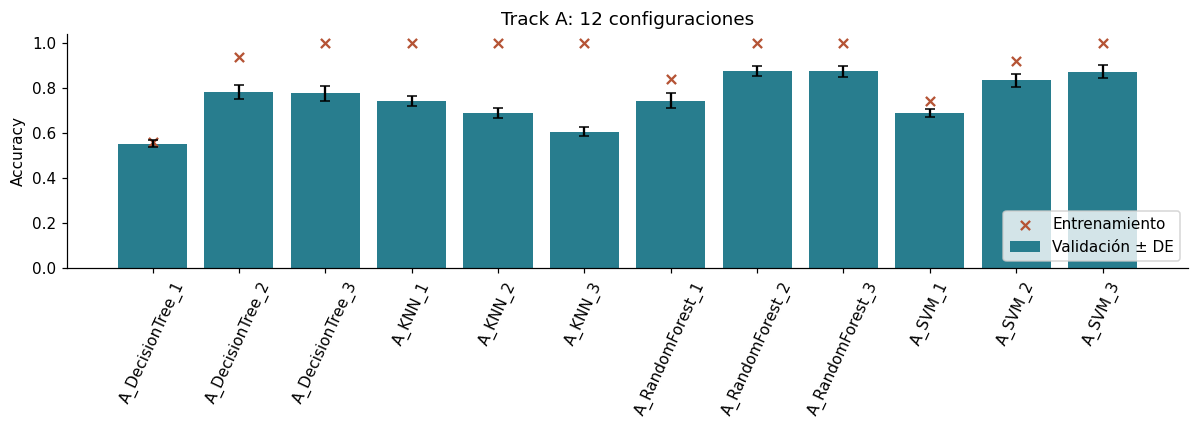

In [13]:
baseline = cross_validate(DummyClassifier(strategy='most_frequent'), X_train_visual, y_train,
                          cv=CV_SPLITS, scoring='accuracy', error_score='raise')
print('Baseline sin aprender características:', np.mean(baseline['test_score']))
results_A, folds_A = run_candidates('A', X_train_visual, y_train, CV_SPLITS, CONFIGS, visual_columns, SEED, N_JOBS)
results_A.to_csv(RESULTS / 'validacion_A.csv', index=False)
folds_A.to_csv(RESULTS / 'folds_A.csv', index=False)
display(rank_candidates(results_A))
plot_validation(results_A, FIGURES / '04_validacion_A.png')


### Interpretar A antes de continuar

Relaciona los histogramas con piezas concretas: ¿qué clases separa el área?, ¿cuáles comparten excentricidad? Un histograma solapado no demuestra que una variable sea inútil en combinación.

En la tabla identifica el ganador **de validación**, el peor y un cambio concreto entre configuraciones del mismo modelo. Compara entrenamiento y validación: una brecha grande es compatible con sobreajuste, pero no basta para atribuir causalidad. Los tiempos también importan.

Todavía no calculamos accuracy de prueba: la evaluación final de A se hará junto con B y C después de fijar todas las decisiones.


## 4. Track B · Auditar y limpiar la ficha técnica

La auditoría de esquema y faltantes del CSV completo es descriptiva. Los gráficos por clase, decisiones estadísticas y validación utilizan solo entrenamiento. No vamos a ajustar umbrales ni imputaciones mirando el test.

**Reglas deterministas:** convertir precios quitando `$` y cambiando coma por punto; invalidar dimensiones/pesos/precios no positivos; invalidar studs negativos o no enteros; invalidar años anteriores a 1932 o posteriores a 2026. Se documenta 1932 como inicio de LEGO, no como año mínimo de cada pieza. Para estas ocho piezas se usa un umbral conservador de altura de 30 mm: los 96 mm del CSV no son compatibles con sus dimensiones nominales, próximas a 3,2/9,6 mm. No corregimos automáticamente 96 → 9,6 porque no conocemos la causa del error.

**Valores extremos:** un peso o precio grande no es imposible por sí solo. Los identificamos mediante IQR dentro de clases en entrenamiento para analizarlos, pero no borramos registros ni usamos su etiqueta al predecir. `RobustScaler` reduce el efecto sobre el centro/escala estimados; no garantiza que los extremos dejen de afectar las distancias.

**Imputación:** mediana por columna aprendida dentro de cada fold. No usar mediana por `label`: al predecir no conocemos la clase.


In [14]:
def clean_inventory(frame):
    clean = frame.copy()
    clean['price'] = pd.to_numeric(clean['price'].astype('string').str.strip()
        .str.replace('$', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')
    for column in ['weight_g', 'height_mm', 'n_studs', 'footprint_mm2', 'year_released']:
        clean[column] = pd.to_numeric(clean[column], errors='coerce')
    for column in ['weight_g', 'height_mm', 'footprint_mm2', 'price']:
        clean.loc[~np.isfinite(clean[column]) | clean[column].le(0), column] = np.nan
    clean.loc[clean.height_mm.gt(30), 'height_mm'] = np.nan
    invalid_studs = ~np.isfinite(clean.n_studs) | clean.n_studs.lt(0) | clean.n_studs.mod(1).ne(0)
    clean.loc[invalid_studs, 'n_studs'] = np.nan
    clean.loc[~clean.year_released.between(1932, 2026), 'year_released'] = np.nan
    for column in ['category', 'finish']:
        clean[column] = clean[column].astype('string').str.strip().str.lower().replace('', pd.NA)
        clean[column] = clean[column].astype(object).where(clean[column].notna(), np.nan)
    # Codificación categórica de un booleano: no confundir ausencia con False.
    clean['is_defective'] = clean['is_defective'].map({True: 'true', False: 'false', 'True': 'true', 'False': 'false'})
    return clean


,tipo_original,faltantes_originales,porcentaje_original,valores_distintos,faltantes_tras_reglas
filename,object,0,0.0,2400,0
label,object,0,0.0,8,0
weight_g,float64,120,5.0,2280,120
height_mm,float64,120,5.0,2244,157
n_studs,float64,192,8.0,6,252
footprint_mm2,float64,96,4.0,2304,96
price,object,144,6.0,89,144
year_released,float64,120,5.0,44,158
category,object,120,5.0,20,120
finish,object,0,0.0,3,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
filename,2400,2400,3001 brick 2x4 261L.png,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,2400,8,3040 roof tile 1x2,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight_g,2280.0,NaN,NaN,NaN,0.928975,1.084891,0.054569,0.426482,0.611737,1.152022,17.097015
height_mm,2280.0,NaN,NaN,NaN,9.43773,11.453744,2.760583,9.217505,9.537661,9.671077,96.0
n_studs,2208.0,NaN,NaN,NaN,2.646739,2.422375,-1.0,1.0,2.0,4.0,8.0
footprint_mm2,2304.0,NaN,NaN,NaN,191.330657,139.073306,56.747442,101.438869,130.1748,255.575674,575.453172
price,2256,89,$0.05,421,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_released,2280.0,NaN,NaN,NaN,1972.008333,156.270345,0.0,1969.0,1979.0,1990.0,3000.0
category,2280,20,brick,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
finish,2400,3,glossy,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


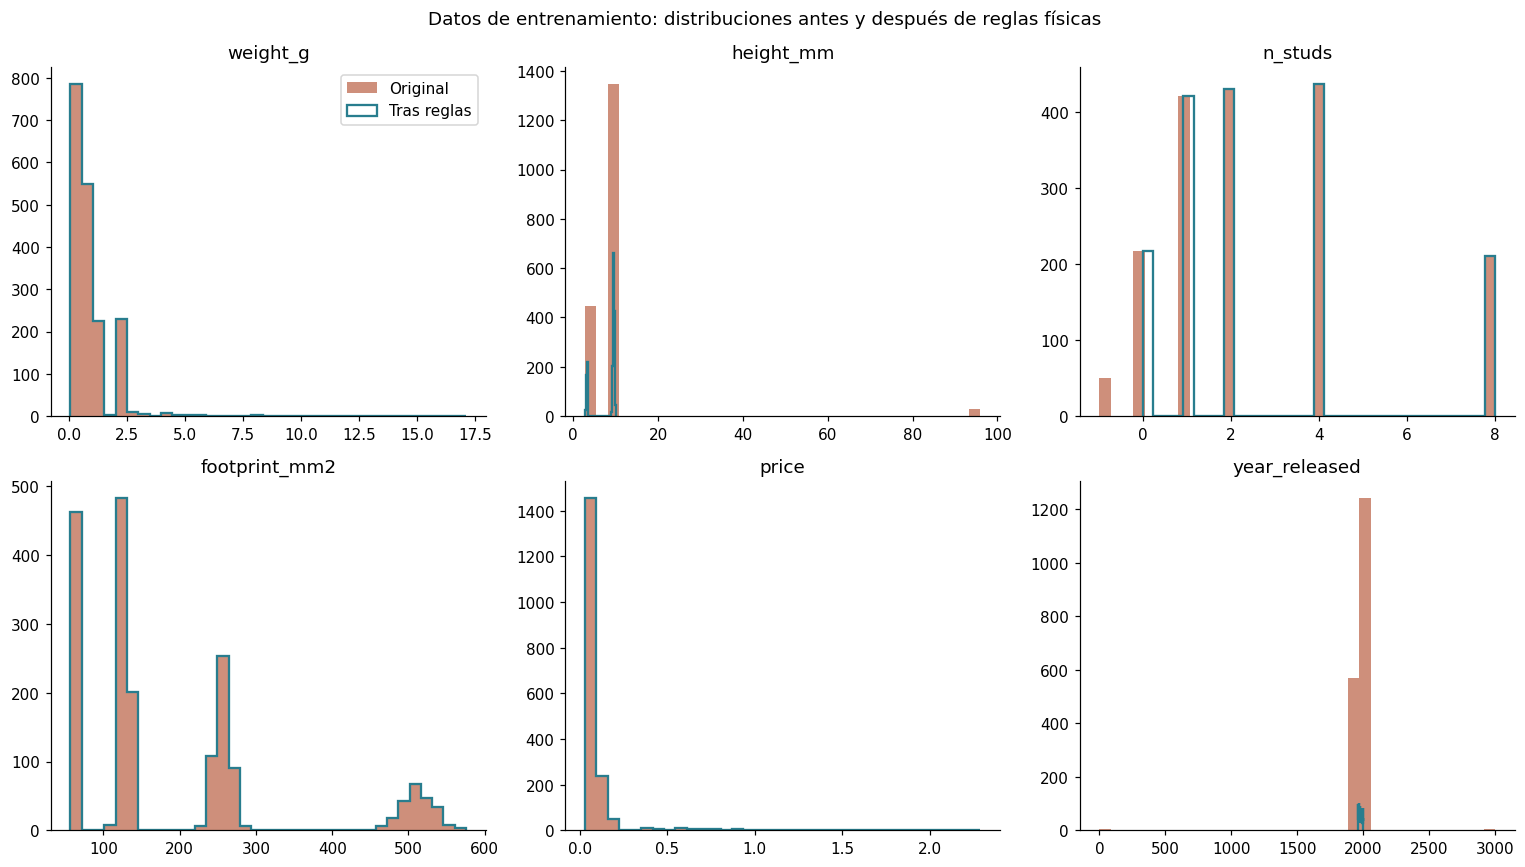

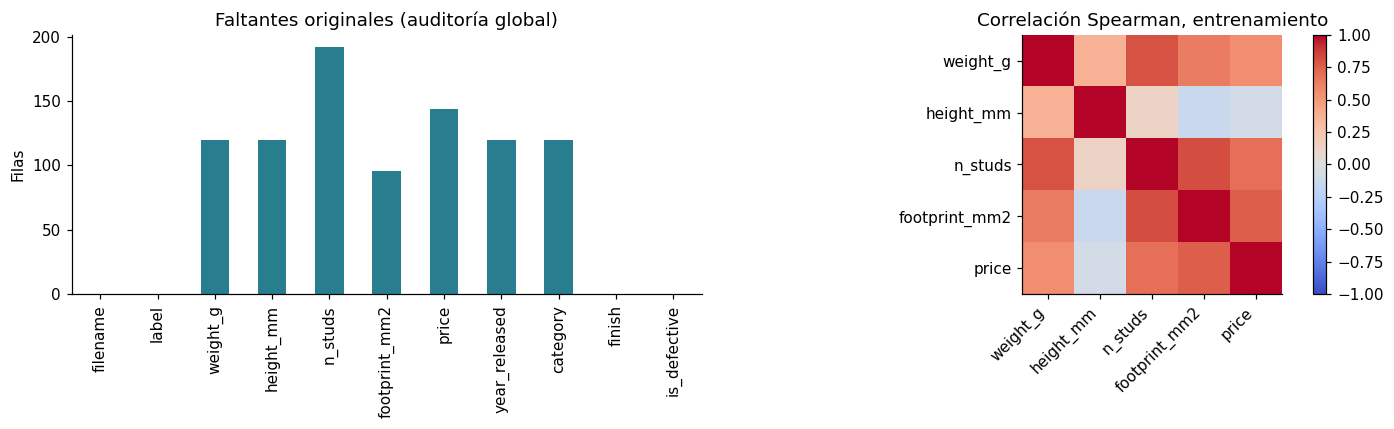

,weight_g,height_mm,n_studs,footprint_mm2,price
label,,,,,
3001 brick 2x4,2.318,9.600,8.0,512.881,0.14
3003 brick 2x2,1.211,9.599,4.0,256.238,0.08
3004 brick 1x2,0.695,9.586,2.0,127.656,0.06
3005 brick 1x1,0.436,9.601,1.0,63.558,0.05
3022 Plate 2x2,0.524,3.203,4.0,255.484,0.08
3040 roof tile 1x2,0.708,9.613,2.0,128.016,0.06
3062 Round Brick 1x1,0.422,9.591,1.0,64.093,0.05
3069 Flat Tile 1x2,0.288,3.204,0.0,127.680,0.06


In [15]:
inventory_clean = clean_inventory(dataset)
audit = pd.DataFrame({'tipo_original': inventory_raw.dtypes.astype(str),
                      'faltantes_originales': inventory_raw.isna().sum(),
                      'porcentaje_original': 100 * inventory_raw.isna().mean(),
                      'valores_distintos': inventory_raw.nunique()})
audit['faltantes_tras_reglas'] = inventory_clean[audit.index].isna().sum().to_numpy()
audit.to_csv(RESULTS / 'auditoria_columnas.csv')
display(audit.round(2))
display(inventory_raw.describe(include='all').T)
raw_train = dataset.iloc[train_idx].reset_index(drop=True)
clean_train = inventory_clean.iloc[train_idx].reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column, ax in zip(TABULAR_COLUMNS + ['year_released'], axes.ravel()):
    values = pd.to_numeric(raw_train[column].astype('string').str.replace('$', '', regex=False)
                           .str.replace(',', '.', regex=False), errors='coerce')
    ax.hist(values.dropna(), bins=35, color='#b55435', alpha=.65, label='Original')
    ax.hist(clean_train[column].dropna(), bins=35, histtype='step', color='#287d8e', linewidth=1.5, label='Tras reglas')
    ax.set_title(column)
axes[0, 0].legend()
fig.suptitle('Datos de entrenamiento: distribuciones antes y después de reglas físicas')
plt.tight_layout()
fig.savefig(FIGURES / '05_limpieza_tabular.png')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
audit.faltantes_originales.plot.bar(ax=axes[0], color='#287d8e')
axes[0].set(title='Faltantes originales (auditoría global)', ylabel='Filas')
numeric_corr = clean_train[TABULAR_COLUMNS].corr(method='spearman')
im = axes[1].imshow(numeric_corr, vmin=-1, vmax=1, cmap='coolwarm')
axes[1].set_xticks(range(5), TABULAR_COLUMNS, rotation=45, ha='right')
axes[1].set_yticks(range(5), TABULAR_COLUMNS)
axes[1].set_title('Correlación Spearman, entrenamiento')
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
fig.savefig(FIGURES / '06_faltantes_correlacion.png')
plt.show()
outlier_rows = []
for class_name, group in clean_train.groupby('label'):
    for column in TABULAR_COLUMNS:
        q1, q3 = group[column].quantile([.25, .75])
        iqr = q3 - q1
        unusual = group[column].lt(q1 - 1.5 * iqr) | group[column].gt(q3 + 1.5 * iqr)
        outlier_rows.append({'label': class_name, 'column': column, 'atipicos_IQR': int(unusual.sum())})
pd.DataFrame(outlier_rows).to_csv(RESULTS / 'atipicos_por_clase_train.csv', index=False)
display(clean_train.groupby('label')[TABULAR_COLUMNS].median().round(3))


### Selección tabular: disponibilidad, sentido físico y contraste empírico

Conservamos `weight_g`, `height_mm`, `n_studs`, `footprint_mm2` y `price`: son magnitudes disponibles en la ficha del escenario. Peso y superficie pueden correlacionarse; no los eliminamos automáticamente, pues grosor y geometría pueden hacerlos complementarios. El precio puede aportar ruido y su utilidad depende de que exista antes de clasificar.

Excluimos `filename`, `path`, `image_hash` y `label`. `category` queda fuera por instrucción expresa. Excluimos inicialmente año, acabado y defecto porque no describen directamente la geometría que define la clase y podrían capturar particularidades del inventario. Más abajo contrastamos añadir estas tres variables con el ganador de B en validación; es una comprobación de la decisión, no una demostración universal de irrelevancia. No cambiamos el resultado principal después de ver test.

Normalizamos y codificamos las categorías solo en esos experimentos adicionales, con valores desconocidos tolerados. En el track principal no hay columnas categóricas que codificar.


B_SVM_1: accuracy CV = 0.5094 ± 0.0161
B_SVM_2: accuracy CV = 0.7000 ± 0.0111
B_SVM_3: accuracy CV = 0.7089 ± 0.0125
B_RandomForest_1: accuracy CV = 0.7432 ± 0.0123
B_RandomForest_2: accuracy CV = 0.7490 ± 0.0176
B_RandomForest_3: accuracy CV = 0.7411 ± 0.0233
B_DecisionTree_1: accuracy CV = 0.5255 ± 0.1020
B_DecisionTree_2: accuracy CV = 0.7495 ± 0.0059
B_DecisionTree_3: accuracy CV = 0.7490 ± 0.0213
B_KNN_1: accuracy CV = 0.7109 ± 0.0173
B_KNN_2: accuracy CV = 0.7010 ± 0.0129
B_KNN_3: accuracy CV = 0.7151 ± 0.0091


,id,track,model,config,params,cv_accuracy,cv_std,cv_f1_macro,train_accuracy,fit_seconds,score_seconds
0,B_DecisionTree_2,B,DecisionTree,2,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.749479,0.005938,0.719149,0.824349,0.021519,0.012215
1,B_RandomForest_2,B,RandomForest,2,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es...",0.748958,0.017624,0.748298,0.995964,0.932551,0.042516
2,B_DecisionTree_3,B,DecisionTree,3,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.748958,0.021284,0.748369,1.000000,0.023771,0.011735
3,B_RandomForest_1,B,RandomForest,1,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est...",0.743229,0.012298,0.739976,0.817318,0.697330,0.034999
4,B_RandomForest_3,B,RandomForest,3,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.741146,0.023336,0.740255,1.000000,0.985787,0.042623
5,B_KNN_3,B,KNN,3,"{""metric"": ""minkowski"", ""n_neighbors"": 15, ""p""...",0.715104,0.009133,0.713491,1.000000,0.026737,0.031489
6,B_KNN_1,B,KNN,1,"{""metric"": ""minkowski"", ""n_neighbors"": 3, ""p"":...",0.710938,0.017274,0.710864,1.000000,0.028560,0.025914
7,B_SVM_3,B,SVM,3,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.708854,0.012543,0.657326,0.729557,0.056532,0.044880
8,B_KNN_2,B,KNN,2,"{""metric"": ""minkowski"", ""n_neighbors"": 7, ""p"":...",0.701042,0.012942,0.699859,1.000000,0.027498,0.030202
9,B_SVM_2,B,SVM,2,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.700000,0.011110,0.627731,0.712240,0.123752,0.065217


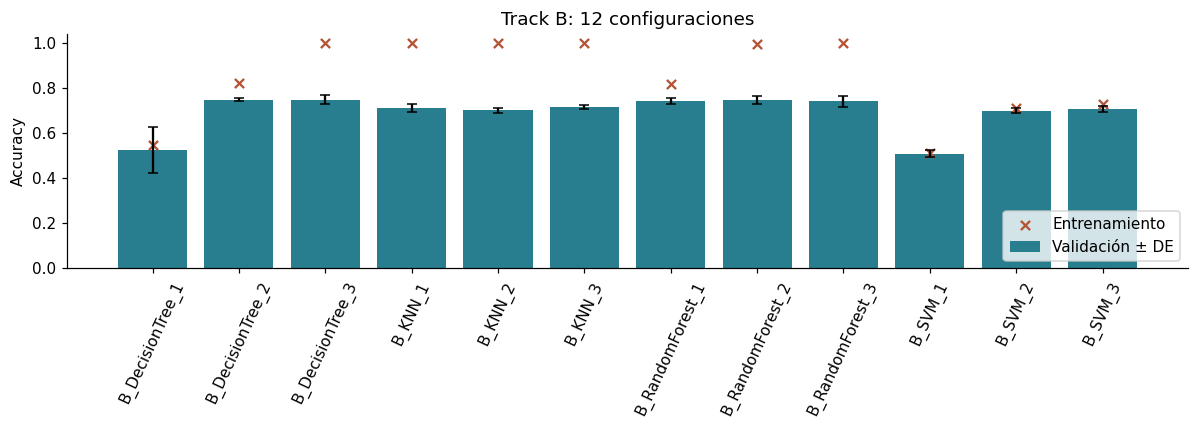

B_category_DecisionTree_1: accuracy CV = 0.9625 ± 0.0114
B_aux_DecisionTree_1: accuracy CV = 0.7432 ± 0.0128


,track,model,params,cv_accuracy,cv_std
0,B,DecisionTree,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.749479,0.005938
1,B_category,DecisionTree,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.9625,0.011441
2,B_aux,DecisionTree,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.743229,0.012837


Cambio CV al incluir auxiliares (puntos porcentuales): -0.62


In [16]:
results_B, folds_B = run_candidates('B', clean_train, y_train, CV_SPLITS, CONFIGS, visual_columns, SEED, N_JOBS)
results_B.to_csv(RESULTS / 'validacion_B.csv', index=False)
folds_B.to_csv(RESULTS / 'folds_B.csv', index=False)
display(rank_candidates(results_B))
plot_validation(results_B, FIGURES / '07_validacion_B.png')
best_B = rank_candidates(results_B).iloc[0]
diagnostic_configs = {best_B.model: [json.loads(best_B.params)]}
category_cv, category_folds = run_candidates('B_category', clean_train, y_train, CV_SPLITS,
                                           diagnostic_configs, visual_columns, SEED, N_JOBS)
aux_cv, aux_folds = run_candidates('B_aux', clean_train, y_train, CV_SPLITS,
                                 diagnostic_configs, visual_columns, SEED, N_JOBS)
diagnostics = pd.concat([best_B.to_frame().T, category_cv, aux_cv], ignore_index=True)
diagnostics.to_csv(RESULTS / 'diagnosticos_tabulares_cv.csv', index=False)
category_folds.to_csv(RESULTS / 'folds_category.csv', index=False)
aux_folds.to_csv(RESULTS / 'folds_auxiliares.csv', index=False)
display(diagnostics[['track', 'model', 'params', 'cv_accuracy', 'cv_std']])
print('Cambio CV al incluir auxiliares (puntos porcentuales):',
      round(100 * (aux_cv.cv_accuracy.iloc[0] - best_B.cv_accuracy), 2))


## 5. Track C · Combinar información complementaria

Concatenamos por `filename` las características visuales y la ficha limpia. A/B/C conservan las mismas filas y folds.

Para reducir redundancia visual, retenemos el **25% de coordenadas con mayor F de ANOVA dentro de cada fold**, junto con las cinco variables tabulares justificadas antes. ANOVA compara variación entre clases con variación dentro de las clases, variable a variable. Es un criterio sencillo y reproducible, no detecta todas las interacciones ni garantiza eliminar correlación. El 25% es una decisión previa para reducir dimensionalidad; no se ajusta mirando test. Fuente: [selección univariante de scikit-learn](https://scikit-learn.org/stable/modules/feature_selection.html#univariate-feature-selection).

Implementamos el cálculo de F con manejo explícito de casos degenerados: una coordenada constante recibe F=0 y p=1; si separa clases con varianza interna exactamente cero, recibe el máximo float finito y p=0 para ordenar sin avisos. Para casos regulares se usa el cociente ANOVA habitual. Los p-valores se conservan por trazabilidad, no se interpretan como pruebas de significación múltiple. Referencia: [ANOVA de un factor en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html).

Después de escalar cada bloque, dividimos sus coordenadas por la raíz del número de características del bloque. Esto limita que miles de coordenadas HOG dominen las distancias frente a cinco variables tabulares. No garantiza igual varianza, porque el escalado robusto y la correlación no la fijan a uno. En árboles, este factor positivo apenas cambia las particiones posibles.

**Pregunta que resuelve el experimento:** ¿la selección y combinación aportan una mejora frente a A/B con el mismo presupuesto de doce configuraciones? Si C mejora, no podemos atribuir toda la diferencia exclusivamente a la fusión, porque también hay selección y reponderación visual; se declara esta limitación y sería necesario un estudio adicional de ablación para aislar cada efecto.


C_SVM_1: accuracy CV = 0.5719 ± 0.0091
C_SVM_2: accuracy CV = 0.7224 ± 0.0146
C_SVM_3: accuracy CV = 0.8104 ± 0.0145
C_RandomForest_1: accuracy CV = 0.8656 ± 0.0210
C_RandomForest_2: accuracy CV = 0.9089 ± 0.0195
C_RandomForest_3: accuracy CV = 0.9104 ± 0.0187
C_DecisionTree_1: accuracy CV = 0.6219 ± 0.1043
C_DecisionTree_2: accuracy CV = 0.8766 ± 0.0100
C_DecisionTree_3: accuracy CV = 0.8797 ± 0.0081
C_KNN_1: accuracy CV = 0.7953 ± 0.0221
C_KNN_2: accuracy CV = 0.7953 ± 0.0095
C_KNN_3: accuracy CV = 0.7714 ± 0.0129


,id,track,model,config,params,cv_accuracy,cv_std,cv_f1_macro,train_accuracy,fit_seconds,score_seconds
0,C_RandomForest_3,C,RandomForest,3,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.910417,0.018652,0.909634,1.000000,2.885009,0.081055
1,C_RandomForest_2,C,RandomForest,2,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es...",0.908854,0.019488,0.907959,0.998828,2.347563,0.075360
2,C_DecisionTree_3,C,DecisionTree,3,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.879687,0.008111,0.879799,1.000000,0.618255,0.040215
3,C_DecisionTree_2,C,DecisionTree,2,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.876563,0.010018,0.876027,0.932161,0.595235,0.041759
4,C_RandomForest_1,C,RandomForest,1,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est...",0.865625,0.021044,0.864694,0.892578,2.073124,0.080394
5,C_SVM_3,C,SVM,3,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.810417,0.014546,0.808830,0.862240,0.710750,0.254218
6,C_KNN_2,C,KNN,2,"{""metric"": ""minkowski"", ""n_neighbors"": 7, ""p"":...",0.795312,0.009497,0.795137,1.000000,0.486585,0.067903
7,C_KNN_1,C,KNN,1,"{""metric"": ""minkowski"", ""n_neighbors"": 3, ""p"":...",0.795312,0.022066,0.795810,1.000000,0.740990,0.116635
8,C_KNN_3,C,KNN,3,"{""metric"": ""minkowski"", ""n_neighbors"": 15, ""p""...",0.771354,0.012942,0.770665,1.000000,0.471518,0.070191
9,C_SVM_2,C,SVM,2,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.722396,0.014569,0.668672,0.739844,1.050371,0.373941


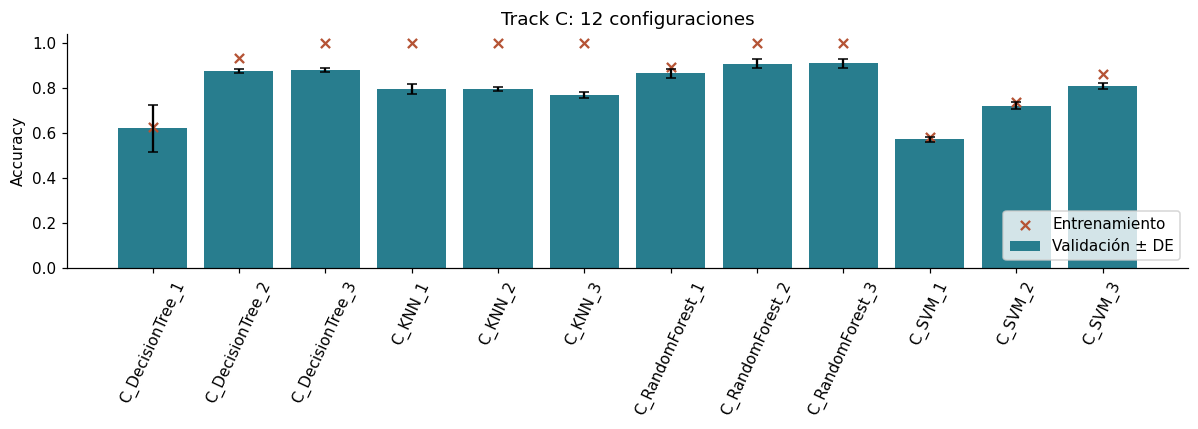

In [17]:
tabular_by_name = inventory_clean.set_index('filename')
combined = visual.join(tabular_by_name.drop(columns=['label', 'path', 'image_hash'], errors='ignore'), how='left', validate='one_to_one')
X_train_combined = combined.loc[train_data.filename].reset_index(drop=True)
assert len(X_train_combined) == len(y_train)
assert not {'filename', 'label', 'category'} & set(TABULAR_COLUMNS + visual_columns)
results_C, folds_C = run_candidates('C', X_train_combined, y_train, CV_SPLITS, CONFIGS, visual_columns, SEED, N_JOBS)
results_C.to_csv(RESULTS / 'validacion_C.csv', index=False)
folds_C.to_csv(RESULTS / 'folds_C.csv', index=False)
display(rank_candidates(results_C))
plot_validation(results_C, FIGURES / '08_validacion_C.png')


## 6. Congelar el ranking antes de abrir el test

Seleccionamos el mejor candidato de cada familia en cada track: 12 finalistas. Además, tomamos el top 3 del ranking global de las 36 configuraciones, aunque dos pertenezcan a la misma familia. Evaluaremos la unión de ambos conjuntos y reutilizaremos resultados si coinciden.

El ranking top 10 sigue ordenado por **validación**, incluso si el test cambia el orden. El experimento con category se evalúa aparte con exactamente la familia e hiperparámetros ya fijados para el ganador de B. No asumimos que su accuracy aumentará: medimos el cambio con su signo.


In [18]:
all_results = pd.concat([results_A, results_B, results_C], ignore_index=True)
assert len(all_results) == 36 and all_results.groupby('track').size().eq(12).all()
ranking = rank_candidates(all_results)
top10 = ranking.head(10).copy()
finalists = ranking.drop_duplicates(['track', 'model'])
selected_ids = set(finalists.id) | set(ranking.head(3).id)
frozen_selection = ranking[ranking.id.isin(selected_ids)].copy()
ranking.to_csv(RESULTS / 'ranking_36_validacion.csv', index=False)
top10.to_csv(RESULTS / 'ranking_top10.csv', index=False)
(RESULTS / 'seleccion_antes_del_test.json').write_text(json.dumps({
    'ids': frozen_selection.id.tolist(), 'top3': ranking.head(3).id.tolist(),
    'criterion': 'accuracy CV descendente, DE ascendente, id ascendente',
    'seed': SEED, 'configs': CONFIGS, 'category_base': str(best_B.id),
    'csv_sha256': hashlib.sha256(CSV_PATH.read_bytes()).hexdigest(),
    'feature_fingerprint': fingerprint, 'versions': versions}, indent=2), encoding='utf-8')
display(top10[['id', 'params', 'cv_accuracy', 'cv_std', 'cv_f1_macro', 'fit_seconds']])
print('Candidatos finales a evaluar:', len(frozen_selection))


,id,params,cv_accuracy,cv_std,cv_f1_macro,fit_seconds
0,C_RandomForest_3,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.910417,0.018652,0.909634,2.885009
1,C_RandomForest_2,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es...",0.908854,0.019488,0.907959,2.347563
2,C_DecisionTree_3,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.879687,0.008111,0.879799,0.618255
3,C_DecisionTree_2,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.876563,0.010018,0.876027,0.595235
4,A_RandomForest_2,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es...",0.876042,0.023910,0.874721,6.241670
5,A_RandomForest_3,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.874479,0.025073,0.873609,6.345932
6,A_SVM_3,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.873958,0.028384,0.872626,3.004943
7,C_RandomForest_1,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est...",0.865625,0.021044,0.864694,2.073124
8,A_SVM_2,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.834896,0.027412,0.833426,3.082237
9,C_SVM_3,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.810417,0.014546,0.808830,0.710750


Candidatos finales a evaluar: 13


In [19]:
# Primera evaluación de prueba: todas las decisiones anteriores ya están cerradas.
y_test = dataset.iloc[test_idx].label.reset_index(drop=True)
test_names = dataset.iloc[test_idx].filename.reset_index(drop=True)
X_train = {'A': X_train_visual, 'B': clean_train, 'C': X_train_combined}
X_test = {'A': visual.loc[test_names].reset_index(drop=True),
          'B': inventory_clean.iloc[test_idx].reset_index(drop=True),
          'C': combined.loc[test_names].reset_index(drop=True)}
fitted_models, predictions, evaluations = {}, {}, []
for row in frozen_selection.itertuples(index=False):
    estimator = build_pipeline(row.track, row.model, json.loads(row.params), visual_columns, SEED)
    start = time.perf_counter()
    with threadpool_limits(limits=1):
        estimator.fit(X_train[row.track], y_train)
    fit_time = time.perf_counter() - start
    start = time.perf_counter()
    with threadpool_limits(limits=1):
        predicted = estimator.predict(X_test[row.track])
    predict_time = time.perf_counter() - start
    evaluations.append({'id': row.id, 'track': row.track, 'model': row.model,
                        'cv_accuracy': row.cv_accuracy, 'cv_std': row.cv_std,
                        'test_accuracy': accuracy_score(y_test, predicted),
                        'test_f1_macro': f1_score(y_test, predicted, average='macro'),
                        'fit_seconds_final': fit_time, 'predict_seconds_test': predict_time})
    fitted_models[row.id], predictions[row.id] = estimator, predicted
    pd.DataFrame({'filename': test_names, 'real': y_test, 'prediccion': predicted}).to_csv(RESULTS / f'predicciones_{row.id}.csv', index=False)
    pd.DataFrame(classification_report(y_test, predicted, labels=labels, output_dict=True, zero_division=0)).T.to_csv(RESULTS / f'metricas_clase_{row.id}.csv')
test_results = pd.DataFrame(evaluations)
test_results.to_csv(RESULTS / 'evaluacion_test.csv', index=False)
display(test_results)

category_pipeline = build_pipeline('B_category', best_B.model, json.loads(best_B.params), visual_columns, SEED)
with threadpool_limits(limits=1):
    category_pipeline.fit(clean_train, y_train)
    category_prediction = category_pipeline.predict(X_test['B'])
category_comparison = pd.DataFrame([
    {'scenario': 'sin category', 'cv_accuracy': best_B.cv_accuracy,
     'test_accuracy': accuracy_score(y_test, predictions[best_B.id])},
    {'scenario': 'con category (solo diagnóstico)', 'cv_accuracy': category_cv.cv_accuracy.iloc[0],
     'test_accuracy': accuracy_score(y_test, category_prediction)}])
category_comparison.to_csv(RESULTS / 'comparacion_category.csv', index=False)
pd.DataFrame({'filename': test_names, 'real': y_test, 'prediccion': category_prediction}).to_csv(RESULTS / 'predicciones_category.csv', index=False)
display(category_comparison)
category_delta = 100 * (category_comparison.test_accuracy.iloc[1] - category_comparison.test_accuracy.iloc[0])
print(f'Cambio al incluir category: {category_delta:+.2f} puntos porcentuales en test.')


,id,track,model,cv_accuracy,cv_std,test_accuracy,test_f1_macro,fit_seconds_final,predict_seconds_test
0,C_RandomForest_3,C,RandomForest,0.910417,0.018652,0.922917,0.922596,2.074247,0.050365
1,C_RandomForest_2,C,RandomForest,0.908854,0.019488,0.933333,0.933100,1.983002,0.052781
2,C_DecisionTree_3,C,DecisionTree,0.879687,0.008111,0.895833,0.895344,0.512394,0.024867
3,A_RandomForest_2,A,RandomForest,0.876042,0.023910,0.908333,0.907664,6.085012,0.048770
4,A_SVM_3,A,SVM,0.873958,0.028384,0.891667,0.889873,2.290651,1.098955
5,C_SVM_3,C,SVM,0.810417,0.014546,0.829167,0.826250,0.566322,0.220645
6,C_KNN_2,C,KNN,0.795312,0.009497,0.793750,0.790377,0.349621,0.061168
7,A_DecisionTree_2,A,DecisionTree,0.784375,0.031862,0.804167,0.802895,1.322655,0.023028
8,B_DecisionTree_2,B,DecisionTree,0.749479,0.005938,0.733333,0.693384,0.017496,0.004764
9,B_RandomForest_2,B,RandomForest,0.748958,0.017624,0.739583,0.738902,0.740462,0.025373


,scenario,cv_accuracy,test_accuracy
0,sin category,0.749479,0.733333
1,con category (solo diagnóstico),0.962500,0.968750


Cambio al incluir category: +23.54 puntos porcentuales en test.


### Comparación, estabilidad y coste

Las barras de validación comparan el proceso de selección; las de prueba muestran cómo generalizan las configuraciones elegidas. No son resultados de reoptimizar sobre test. Para el tiempo total de imagen suma también la extracción de características; los tiempos de ajuste por sí solos no incluyen descarga ni extracción.

Una mejora pequeña, con pocos errores de diferencia, no demuestra una superioridad general. Las desviaciones de CV ayudan a contextualizarla, pero los folds comparten observaciones de entrenamiento y no son réplicas independientes.


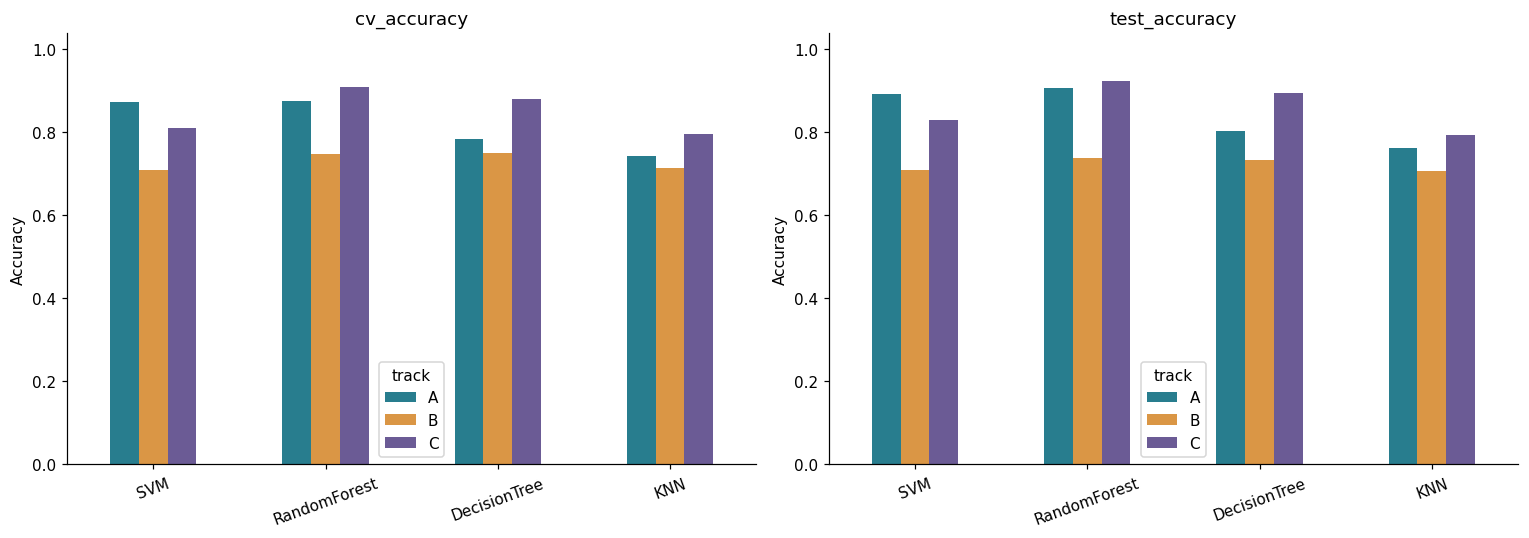

,id,track,model,params,cv_accuracy,cv_std,test_accuracy,test_f1_macro,fit_seconds_final,predict_seconds_test
0,C_RandomForest_3,C,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.910417,0.018652,0.922917,0.922596,2.074247,0.050365
1,A_RandomForest_2,A,RandomForest,"{""max_depth"": 15, ""min_samples_leaf"": 1, ""n_es...",0.876042,0.023910,0.908333,0.907664,6.085012,0.048770
2,B_DecisionTree_2,B,DecisionTree,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.749479,0.005938,0.733333,0.693384,0.017496,0.004764


In [20]:
final_comparison = finalists[['id', 'track', 'model', 'cv_accuracy']].merge(
    test_results[['id', 'test_accuracy', 'test_f1_macro']], on='id', validate='one_to_one')
final_comparison.to_csv(RESULTS / 'comparacion_12_finalistas.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for metric, ax in zip(['cv_accuracy', 'test_accuracy'], axes):
    final_comparison.pivot(index='model', columns='track', values=metric).reindex(MODEL_NAMES).plot.bar(
        ax=ax, color=['#287d8e', '#da9645', '#6b5b95'], ylim=(0, 1.04))
    ax.set(title=metric, xlabel='', ylabel='Accuracy')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
fig.savefig(FIGURES / '09_comparacion_tracks.png')
plt.show()

best_by_track = ranking.drop_duplicates('track')
track_comparison = best_by_track[['id', 'track', 'model', 'params', 'cv_accuracy', 'cv_std']].merge(
    test_results[['id', 'test_accuracy', 'test_f1_macro', 'fit_seconds_final', 'predict_seconds_test']], on='id')
display(track_comparison)
track_comparison.to_csv(RESULTS / 'ganador_por_track.csv', index=False)


### Matrices de confusión y ejemplos concretos

En cada matriz, las filas son clases reales y las columnas predicciones. Mostramos conteos; todas usan el mismo orden de clases y el mismo conjunto de prueba. El código guarda también las matrices normalizadas por fila.

Los ejemplos de error sirven para interpretar el modelo una vez concluida la evaluación. No se utilizan ahora para rediseñar las características y volver a presentar el mismo test como independiente.


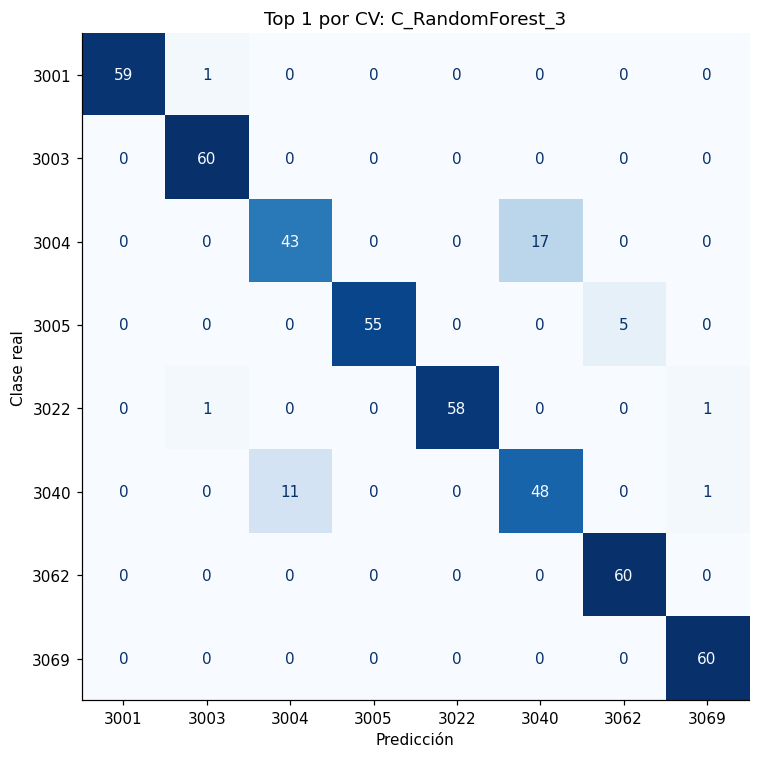

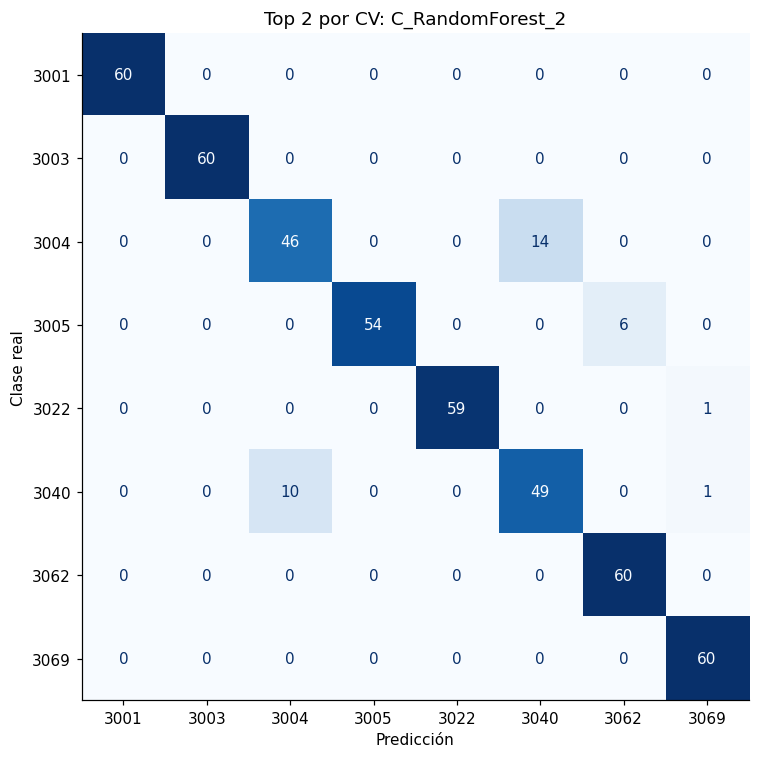

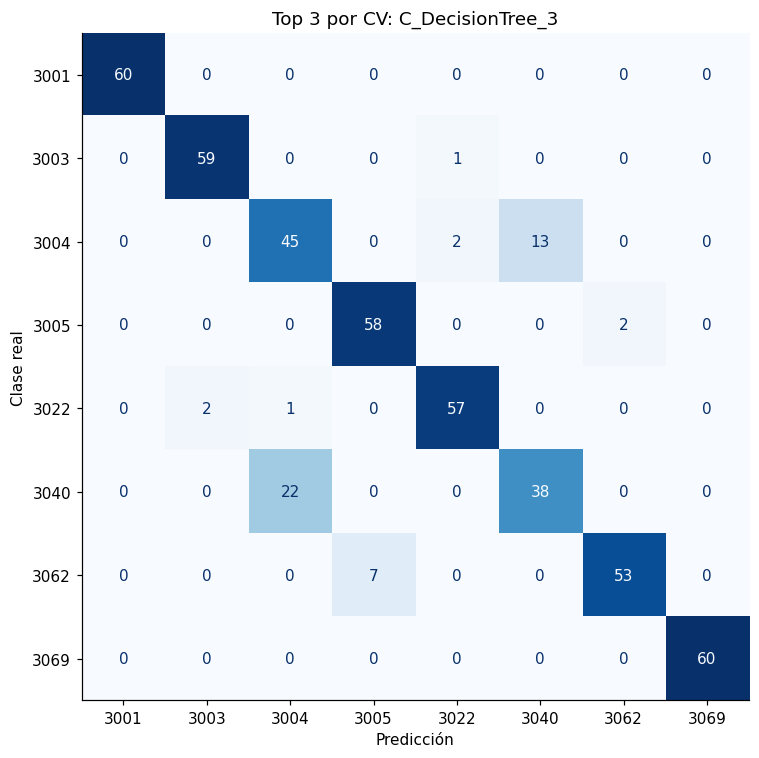

,id,real,prediccion,errores
18,C_DecisionTree_3,3040 roof tile 1x2,3004 brick 1x2,22
1,C_RandomForest_3,3004 brick 1x2,3040 roof tile 1x2,17
7,C_RandomForest_2,3004 brick 1x2,3040 roof tile 1x2,14
14,C_DecisionTree_3,3004 brick 1x2,3040 roof tile 1x2,13
5,C_RandomForest_3,3040 roof tile 1x2,3004 brick 1x2,11
10,C_RandomForest_2,3040 roof tile 1x2,3004 brick 1x2,10
19,C_DecisionTree_3,3062 Round Brick 1x1,3005 brick 1x1,7
8,C_RandomForest_2,3005 brick 1x1,3062 Round Brick 1x1,6
2,C_RandomForest_3,3005 brick 1x1,3062 Round Brick 1x1,5
15,C_DecisionTree_3,3005 brick 1x1,3062 Round Brick 1x1,2


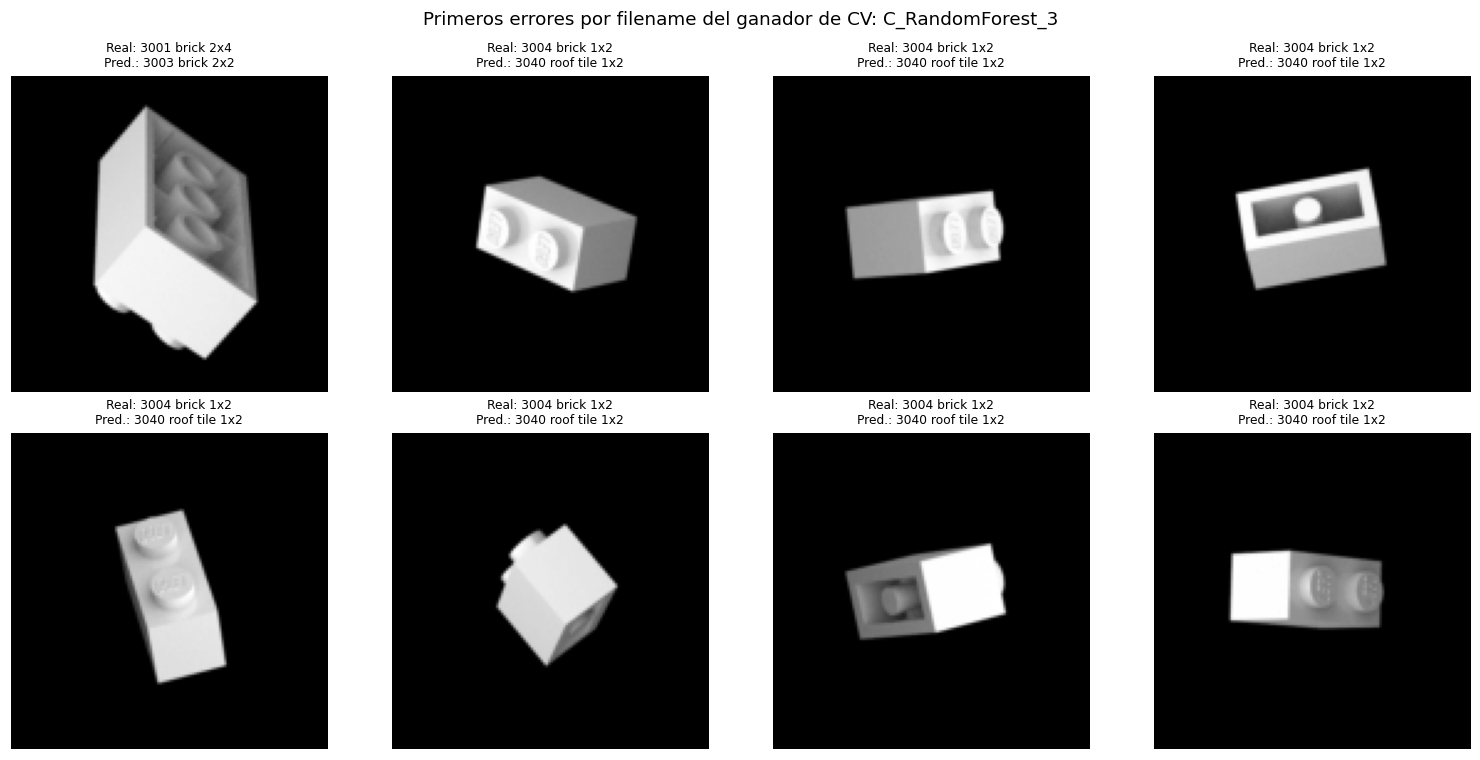

In [21]:
confusion_rows = []
for position, row in enumerate(ranking.head(3).itertuples(index=False), start=1):
    cm = confusion_matrix(y_test, predictions[row.id], labels=labels)
    pd.DataFrame(cm, index=labels, columns=labels).to_csv(RESULTS / f'matriz_{row.id}.csv')
    normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    pd.DataFrame(normalized, index=labels, columns=labels).to_csv(RESULTS / f'matriz_normalizada_{row.id}.csv')
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm, display_labels=short_labels).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Top {position} por CV: {row.id}')
    ax.set(xlabel='Predicción', ylabel='Clase real')
    plt.tight_layout()
    fig.savefig(FIGURES / f'10_matriz_top{position}.png')
    plt.show()
    for actual in range(len(labels)):
        for predicted in range(len(labels)):
            if actual != predicted and cm[actual, predicted]:
                confusion_rows.append({'id': row.id, 'real': labels[actual], 'prediccion': labels[predicted],
                                       'errores': int(cm[actual, predicted])})
confusions = pd.DataFrame(confusion_rows, columns=['id', 'real', 'prediccion', 'errores']).sort_values('errores', ascending=False)
confusions.to_csv(RESULTS / 'confusiones_top3.csv', index=False)
display(confusions.head(12))
winner_id = ranking.iloc[0].id
error_indices = np.flatnonzero(np.asarray(predictions[winner_id]) != y_test.to_numpy())[:8]
if len(error_indices):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, position in zip(axes.ravel(), error_indices):
        ax.imshow(load_gray(dataset.iloc[test_idx[position]].path), cmap='gray')
        ax.set_title(f'Real: {y_test.iloc[position]}\nPred.: {predictions[winner_id][position]}', fontsize=8)
    fig.suptitle(f'Primeros errores por filename del ganador de CV: {winner_id}')
    plt.tight_layout()
    fig.savefig(FIGURES / '11_ejemplos_errores.png')
    plt.show()
else:
    print('El ganador por CV no cometió errores en este test. No implica perfección fuera de esta muestra.')


### Qué seleccionó realmente C

Este listado se obtiene del selector ajustado solo sobre entrenamiento completo. La selección puede variar entre folds y modelos comparten el mismo selector univariante. Un score alto no demuestra causalidad ni elimina redundancia; el archivo completo permite comprobar cuántas medidas geométricas sobrevivieron frente a coordenadas HOG.


In [22]:
best_C_id = best_by_track.loc[best_by_track.track.eq('C'), 'id'].iloc[0]
visual_selector = fitted_models[best_C_id].named_steps['preprocess'].named_transformers_['visual'].named_steps['selector']
selected_features = pd.DataFrame({'feature': visual_columns, 'F_ANOVA_train': visual_selector.scores_,
                                  'selected': visual_selector.get_support()})
selected_features.to_csv(RESULTS / 'seleccion_visual_C.csv', index=False)
display(selected_features[selected_features.feature.isin(GEOMETRY_COLUMNS)])
print('Coordenadas visuales conservadas:', int(selected_features.selected.sum()), '| tabulares:', len(TABULAR_COLUMNS))


,feature,F_ANOVA_train,selected
1764,area_fraction,2008.066276,True
1765,aspect_ratio,15.808180,False
1766,solidity,5.057103,False
1767,eccentricity,194.512562,True
1768,extent,27.531073,False
1769,circularity,30.807365,False


Coordenadas visuales conservadas: 443 | tabulares: 5


## 7. Informe y exportación

El informe se genera **después** de todas las ejecuciones. Incluye decisiones, resultados reales, preguntas de análisis y las figuras. Se llama `respuesta_borrador.pdf`: completa tu autoría, revisa las interpretaciones solicitadas, incorpora tus observaciones y el anexo de IA antes de convertirlo en `respuesta.pdf` final. No basta con entregar automáticamente tablas y código.

El PDF y el Markdown comparten contenido. El ZIP incluye evidencia numérica y figuras, pero excluye imágenes fuente, cachés y modelos serializados. Conserva el notebook ejecutado por separado.


### Tu interpretación y autoría

Tras ejecutar y revisar las figuras, completa estos campos con tus palabras. Las respuestas automáticas ya aportan metodología y cifras; aquí debes conectar esa evidencia con piezas, patrones y limitaciones concretos. Introduce en `AI_ANNEX` los prompts y respuestas relevantes completos (también puedes anexarlos después con tu editor).

Mientras `FINAL_REPORT=False` se genera un borrador. Para generar `respuesta.pdf`, completa autoría, las 14 interpretaciones y el anexo y cambia a `True`. Basta con volver a ejecutar desde esta celda hasta el final; no necesitas reentrenar. Esta comprobación verifica que los campos estén presentes, no evalúa la calidad de tus respuestas.


In [23]:
REPORT_AUTHOR = ''
FINAL_REPORT = False
PERSONAL_ANALYSIS = {question: '' for question in [
    'A.a', 'A.b', 'A.c', 'A.d', 'A.e', 'A.f',
    'B.a', 'B.b', 'B.c', 'B.d', 'C.a', 'C.b', 'C.c', 'C.d']}
# Ejemplo de edición: PERSONAL_ANALYSIS['A.a'] = 'En la figura 03 observo ...'
AI_ANNEX = ''


In [24]:
def markdown_table(frame):
    # Sin dependencia adicional de tabulate.
    values = frame.copy()
    for column in values:
        values[column] = values[column].map(lambda x: f'{x:.4f}' if isinstance(x, (float, np.floating)) else str(x))
    safe = lambda value: str(value).replace('|', '/').replace('\n', ' ')
    rows = ['| ' + ' | '.join(map(safe, values.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(values.columns)) + ' |']
    rows.extend('| ' + ' | '.join(map(safe, row)) + ' |' for row in values.itertuples(index=False, name=None))
    return '\n'.join(rows)


def render_report(items, directory, final=False):
    from matplotlib import font_manager
    from reportlab.lib import colors
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.pdfbase import pdfmetrics
    from reportlab.pdfbase.ttfonts import TTFont
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as PDFImage, KeepTogether

    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    stem = 'respuesta' if final else 'respuesta_borrador'
    normal_font = font_manager.findfont(font_manager.FontProperties(family='DejaVu Sans'))
    bold_font = font_manager.findfont(font_manager.FontProperties(family='DejaVu Sans', weight='bold'))
    pdfmetrics.registerFont(TTFont('LegoSans', normal_font))
    pdfmetrics.registerFont(TTFont('LegoSansBold', bold_font))
    styles = getSampleStyleSheet()
    styles.add(ParagraphStyle(name='LegoBody', fontName='LegoSans', fontSize=9, leading=13, spaceAfter=7))
    styles.add(ParagraphStyle(name='LegoHeading', fontName='LegoSansBold', fontSize=13, leading=17,
                              textColor=colors.HexColor('#205e6c'), spaceBefore=12, spaceAfter=8, keepWithNext=True))
    styles.add(ParagraphStyle(name='LegoCell', fontName='LegoSans', fontSize=7, leading=10, wordWrap='CJK'))
    styles.add(ParagraphStyle(name='LegoCaption', fontName='LegoSans', fontSize=8, leading=11, spaceAfter=6))
    doc = SimpleDocTemplate(str(directory / f'{stem}.pdf'), pagesize=A4,
                            leftMargin=40, rightMargin=40, topMargin=40, bottomMargin=40,
                            title='DCCubos - Clasificación de piezas LEGO', author='Estudiante de IIC2613')
    story, markdown = [], []
    for kind, content in items:
        if kind == 'heading':
            story.append(Paragraph(escape(content), styles['LegoHeading']))
            markdown.append('## ' + content)
        elif kind == 'paragraph':
            story.append(Paragraph(escape(content).replace('\n', '<br/>'), styles['LegoBody']))
            markdown.append(content)
        elif kind == 'table':
            title, frame = content
            markdown += ['### ' + title, markdown_table(frame)]
            data = [[Paragraph(escape(str(c)), styles['LegoCell']) for c in frame.columns]]
            for row in frame.itertuples(index=False, name=None):
                data.append([Paragraph(escape(f'{value:.4f}' if isinstance(value, (float, np.floating)) else str(value)),
                                       styles['LegoCell']) for value in row])
            widths = [doc.width / len(frame.columns)] * len(frame.columns)
            table = Table(data, colWidths=widths, repeatRows=1, hAlign='LEFT')
            table.setStyle(TableStyle([('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#e2eef0')),
                ('ROWBACKGROUNDS', (0, 1), (-1, -1), [colors.white, colors.HexColor('#f5f7f8')]),
                ('VALIGN', (0, 0), (-1, -1), 'TOP'), ('BOTTOMPADDING', (0, 0), (-1, -1), 5),
                ('TOPPADDING', (0, 0), (-1, -1), 5),
                ('LINEBELOW', (0, 0), (-1, 0), .5, colors.HexColor('#287d8e'))]))
            story += [Paragraph(escape(title), styles['LegoHeading']), table, Spacer(1, 10)]
        elif kind == 'image':
            title, path = content
            with Image.open(path) as picture:
                width, height = picture.size
            factor = min(doc.width / width, (doc.height - 60) / height)
            story.append(KeepTogether([Paragraph(escape(title), styles['LegoCaption']),
                                        PDFImage(str(path), width=width * factor, height=height * factor), Spacer(1, 12)]))
            markdown.append(f'![{title}](figuras/{Path(path).name})')
        else:
            raise ValueError(f'Tipo de informe desconocido: {kind}')

    def footer(canvas, document):
        canvas.setFont('LegoSans', 7)
        canvas.setFillColor(colors.HexColor('#607080'))
        state = 'Informe revisado por el autor' if final else 'BORRADOR - revisar interpretación y autoría'
        canvas.drawString(40, 24, state)
        canvas.drawRightString(A4[0] - 40, 24, str(document.page))

    doc.build(story, onFirstPage=footer, onLaterPages=footer)
    (directory / f'{stem}.md').write_text('\n\n'.join(markdown) + '\n', encoding='utf-8')


In [25]:
questions = {
    'A.a': 'Características: relacionar HOG y las seis medidas con histogramas y piezas concretas.',
    'A.b': 'Escalado: explicar su efecto en SVM/KNN frente a árboles.',
    'A.c': 'Partición: justificar tamaños, representatividad, folds y reserva del test.',
    'A.d': 'Modelos visuales: explicar el ganador a partir de resultados y funcionamiento.',
    'A.e': 'Hiperparámetros: explicar al menos una variación concreta de A.',
    'A.f': 'Mejor y peor modelo/configuración de A: justificar el criterio.',
    'B.a': 'Exploración: discutir problemas de cada columna.',
    'B.b': 'Limpieza: justificar reglas, imputación y posibles consecuencias de no aplicarlas.',
    'B.c': 'Selección: explicar leakage y cuantificar category.',
    'B.d': 'Modelos tabulares: comparar resultados, parámetros y brechas.',
    'C.a': 'Selección combinada: justificar información aportada y redundancia.',
    'C.b': 'Resultados: mejor/peor de C y comparación con A/B.',
    'C.c': 'Complementariedad: discutir información, ruido, coste y limitaciones.',
    'C.d': 'Matrices: interpretar confusiones concretas del top 3.'}
if FINAL_REPORT:
    missing = [key for key in questions if not PERSONAL_ANALYSIS.get(key, '').strip()]
    if not REPORT_AUTHOR.strip() or missing or not AI_ANNEX.strip():
        raise ValueError(f'Completa autoría, anexo de IA e interpretaciones. Preguntas pendientes: {missing}')

report_items = [('heading', 'DCCubos - Clasificación de piezas LEGO'),
    ('paragraph', 'Autor/a: ' + (REPORT_AUTHOR.strip() or 'Completar antes de entregar.')),
    ('paragraph', 'Uso de IA: Codex asistió en planificación, código, documentación y revisión. '
     'Las cifras siguientes se calculan a partir de esta ejecución. La interpretación personal y el anexo deben revisarse por el estudiante.'),
    ('paragraph', 'Estado: ' + ('informe con campos personales completados.' if FINAL_REPORT else
     'borrador de trabajo; contiene indicaciones de interpretación pendientes y no debe entregarse como respuesta final.')),
    ('heading', 'Protocolo y trazabilidad'),
    ('paragraph', f'{len(dataset)} observaciones, {len(labels)} clases; {len(train_idx)} entrenamiento y {len(test_idx)} prueba. '
     f'Semilla {SEED}, {N_SPLITS} folds compartidos. Imputadores, escaladores y selector se ajustan dentro de cada fold. '
     'El ranking se fijó por accuracy CV, desviación e identificador antes de abrir el test. '
     f'Copias exactas adicionales: {int(dataset.image_hash.duplicated().sum())}; se mantienen agrupadas. '
     'Los archivos particion.csv, folds.csv y seleccion_antes_del_test.json permiten auditar la comparación.'),
    ('table', ('Distribución de la partición', split_counts.reset_index())),
    ('table', ('Configuraciones fijas de los cuatro modelos', config_table)),
    ('heading', 'Track A - imagen')]

def personal(question):
    report_items.append(('paragraph', question + ' · ' + questions[question]))
    text = PERSONAL_ANALYSIS.get(question, '').strip()
    report_items.append(('paragraph', ('Interpretación del autor: ' + text) if text else
                          ('Pendiente de interpretación personal: ' + questions[question])))

report_items.append(('paragraph', 'HOG codifica gradientes locales con 9 orientaciones, celdas 16×16, bloques 2×2 y normalización L2-Hys [1]. '
    'Se añaden área relativa, relación anchura/altura, solidez, excentricidad, extensión y circularidad 4πA/P² con perímetro de Crofton [2]. '
    'La máscara usa fondo del borde, Otsu, cierre y componente mayor; cada imagen aporta 1.770 características. '
    'La perspectiva y el fallo de segmentación pueden cambiar estas medidas.'))
personal('A.a')
report_items.append(('paragraph', 'StandardScaler aprende media y desviación de cada coordenada solo en entrenamiento. '
    'SVM y KNN dependen de magnitudes de distancias o márgenes; los árboles mantienen casi las mismas particiones bajo reescalados positivos [3,4].'))
personal('A.b')
report_items.append(('paragraph', 'El 80% permite entrenar/validar y el 20% reserva cientos de observaciones para la evaluación final. '
    'La estratificación conserva clases y los cinco folds reutilizan el entrenamiento sin gastar test en seleccionar parámetros. '
    'Si aparecen duplicados, los grupos tienen prioridad y el porcentaje puede ser aproximado. Esta evaluación mide renders de las ocho clases, no fotos de producción [3].'))
personal('A.c')

for track, table in [('A', results_A), ('B', results_B), ('C', results_C)]:
    if track == 'B':
        report_items.append(('heading', 'Track B - ficha técnica'))
        report_items.append(('table', ('Auditoría de las once columnas', audit.reset_index(names='columna'))))
        report_items.append(('paragraph', 'filename y label identifican y etiquetan; el primero revela literalmente la clase. '
            'Las medidas físicas contienen faltantes; price mezcla símbolos y separadores decimales. '
            'n_studs admite registros negativos, height_mm alturas extremas, year_released años incompatibles y category variantes de escritura. '
            'finish e is_defective se auditan como auxiliares, no como rasgos geométricos principales.'))
        personal('B.a')
        report_items.append(('paragraph', 'Se normalizan precios y categorías; se convierten a ausentes los valores no positivos en medidas físicas/precio, '
            'studs negativos o fraccionarios, alturas superiores a 30 mm y años fuera de 1932–2026 [8]. '
            'El límite de altura es una regla conservadora explícita para estas ocho piezas; no se adivina una corrección por clase. '
            'Se imputan medianas dentro del fold y se usa RobustScaler. No se borran observaciones por ser atípicas: el escalado robusto no elimina su influencia [4].'))
        personal('B.b')
        report_items.append(('paragraph', f'El resultado principal usa {", ".join(TABULAR_COLUMNS)}. '
            'category queda excluida por no estar disponible antes de clasificar. '
            f'Con el mismo modelo/hiperparámetros, añadirla cambia accuracy test en {category_delta:+.2f} puntos porcentuales. '
            'Este cambio no valida su uso operativo y no se incorpora al ranking. '
            f'Añadir año/acabado/defecto cambia accuracy CV en {100*(aux_cv.cv_accuracy.iloc[0]-best_B.cv_accuracy):+.2f} puntos; '
            'es evidencia para discutir la selección inicial, no una prueba de irrelevancia universal.'))
        report_items.append(('table', ('Diagnóstico con/sin category', category_comparison)))
        personal('B.c')
    if track == 'C':
        report_items.append(('heading', 'Track C - combinación'))
        report_items.append(('paragraph', f'Las fuentes se unen por filename y comparten la partición. Se retiene el 25% visual por F de ANOVA '
            f'dentro de cada fold, {int(selected_features.selected.sum())} coordenadas al ajustar en entrenamiento completo, '
            'y se conservan las cinco variables tabulares. Cada bloque escalado se divide por la raíz de su dimensión. '
            'ANOVA selecciona asociaciones individuales con la clase, no causalidad ni todas las interacciones [5]. '
            'La tabla seleccion_visual_C.csv identifica exactamente las variables conservadas.'))
        personal('C.a')
    ordered = rank_candidates(table)
    best, worst = ordered.iloc[0], ordered.iloc[-1]
    best_test = test_results.set_index('id').loc[best.id, 'test_accuracy']
    report_items.append(('paragraph', f'En {track}, mejor configuración por CV: {best.id} ({best.cv_accuracy:.4f} ± {best.cv_std:.4f}); '
        f'accuracy de prueba {best_test:.4f}. Peor por CV: {worst.id} ({worst.cv_accuracy:.4f}). '
        'Mejor/peor se refieren al criterio previo de validación, no a ordenar retrospectivamente por test.'))
    report_items.append(('table', (f'Track {track}: validación de las 12 configuraciones',
        ordered[['id', 'cv_accuracy', 'cv_std', 'train_accuracy', 'cv_f1_macro', 'fit_seconds']].copy())))
    for model in MODEL_NAMES:
        subset = table[table.model.eq(model)].sort_values('config')
        first, last = subset.iloc[0], subset.iloc[-1]
        report_items.append(('paragraph', f'{model}: de configuración 1 a 3, CV pasa de {first.cv_accuracy:.4f} a {last.cv_accuracy:.4f} '
            f'({100*(last.cv_accuracy-first.cv_accuracy):+.2f} puntos). '
            'Consulta la tabla de parámetros para explicar el cambio; no se presupone que mayor complejidad mejore.'))
    report_items.append(('paragraph', 'SVM RBF aprende fronteras no lineales controladas por regularización; el bosque promedia árboles; '
        'el árbol individual puede tener más variabilidad; KNN pondera vecinos por distancia. '
        'Estos mecanismos orientan explicaciones, pero una cifra por sí sola no identifica la causa del rendimiento [6,7,9,10].'))
    if track == 'A':
        for key in ['A.d', 'A.e', 'A.f']:
            personal(key)
    elif track == 'B':
        personal('B.d')
    else:
        personal('C.b')

report_items += [('heading', 'Comparación final y ranking'),
    ('table', ('Doce finalistas: validación y test', final_comparison)),
    ('table', ('Top 10 por validación: configuración e hiperparámetros', top10[['id', 'params', 'cv_accuracy', 'cv_std']])),
    ('table', ('Ganador de cada track, elegido por validación', track_comparison[['track', 'id', 'cv_accuracy', 'test_accuracy', 'fit_seconds_final']]))]
track_scores = track_comparison.set_index('track').test_accuracy
report_items.append(('paragraph', f'El ganador de C cambia accuracy test respecto al ganador de A en {100*(track_scores["C"]-track_scores["A"]):+.2f} puntos '
    f'y respecto a B en {100*(track_scores["C"]-track_scores["B"]):+.2f} puntos. '
    'Una diferencia pequeña exige prudencia. C también cambia selección y peso de los bloques: no aislamos el efecto puro de combinar. '
    'Para decidir en producción hay que valorar extracción visual, mantenimiento del inventario y robustez fuera de los renders; '
    'los tiempos de ajuste no incluyen descarga ni extracción de imágenes.'))
personal('C.c')
if len(confusions):
    report_items.append(('table', ('Confusiones más frecuentes del top 3', confusions.head(12))))
else:
    report_items.append(('paragraph', 'No se observaron confusiones en el top 3 sobre este test. Esto no demuestra ausencia de errores fuera de esta muestra.'))
personal('C.d')
report_items.append(('heading', 'Figuras de esta ejecución'))
for path in sorted(FIGURES.glob('*.png')):
    report_items.append(('image', (path.stem.replace('_', ' '), path)))
report_items += [('heading', 'Referencias'),
    ('paragraph', '[1] N. Dalal y B. Triggs, “Histograms of Oriented Gradients for Human Detection”, CVPR, 2005. '
     'Implementación consultada: https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html'),
    ('paragraph', '[2] scikit-image developers, “skimage.measure: regionprops y perímetro de Crofton”, documentación oficial. '
     'https://scikit-image.org/docs/stable/api/skimage.measure.html'),
    ('paragraph', '[3] scikit-learn developers, “Common pitfalls and recommended practices”, documentación oficial. '
     'https://scikit-learn.org/stable/common_pitfalls.html'),
    ('paragraph', '[4] scikit-learn developers, “Preprocessing data”, documentación oficial. '
     'https://scikit-learn.org/stable/modules/preprocessing.html'),
    ('paragraph', '[5] scikit-learn developers, “Feature selection”, documentación oficial. '
     'https://scikit-learn.org/stable/modules/feature_selection.html'),
    ('paragraph', '[6] scikit-learn developers, “Nearest Neighbors”, documentación oficial. '
     'https://scikit-learn.org/stable/modules/neighbors.html'),
    ('paragraph', '[7] scikit-learn developers, “Support Vector Machines”, documentación oficial. '
     'https://scikit-learn.org/stable/modules/svm.html'),
    ('paragraph', '[8] The LEGO Group, “LEGO History”. https://www.lego.com/en-us/history'),
    ('paragraph', '[9] scikit-learn developers, “Ensembles”, documentación oficial. https://scikit-learn.org/stable/modules/ensemble.html'),
    ('paragraph', '[10] scikit-learn developers, “Decision Trees”, documentación oficial. https://scikit-learn.org/stable/modules/tree.html'),
    ('paragraph', '[11] J. Hazelzet, “Images of LEGO Bricks”, Kaggle. https://www.kaggle.com/datasets/joosthazelzet/lego-brick-images'),
    ('paragraph', '[12] IIC2613, “Tarea 1: Aprendizaje Automático y Reforzado”, 2026-2, enunciado y archivos proporcionados por el curso. '
     'Fuentes web consultadas al preparar el notebook: 22 de septiembre de 2026.'),
    ('heading', 'Anexo: uso de IA'),
    ('paragraph', AI_ANNEX.strip() or 'Pendiente: adjuntar los prompts y respuestas relevantes completos y describir las adaptaciones propias. '
     'El archivo ANEXO_IA.md del repositorio resume el alcance, pero no sustituye las conversaciones completas.'),
    ('heading', 'Versiones de la ejecución'),
    ('table', ('Bibliotecas', pd.DataFrame(versions.items(), columns=['biblioteca', 'version'])))]
render_report(report_items, RESULTS, final=FINAL_REPORT)
print('Informe generado:', RESULTS / ('respuesta.pdf' if FINAL_REPORT else 'respuesta_borrador.pdf'))


Informe generado: /content/resultados/20261001-184851-563077/respuesta_borrador.pdf


In [26]:
archive_path = BASE_DIR / 'resultados_LEGO.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RESULTS.rglob('*')):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(BASE_DIR))
print('ZIP de evidencia:', archive_path)
display(FileLink(str(archive_path)))
try:
    from google.colab import files
except ImportError:
    print('Descarga el ZIP desde la ruta anterior.')
else:
    files.download(str(archive_path))
print('Recuerda descargar también el notebook EJECUTADO desde Archivo → Descargar → .ipynb.')


ZIP de evidencia: /content/resultados_LEGO.zip


/content/resultados_LEGO.zip

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Recuerda descargar también el notebook EJECUTADO desde Archivo → Descargar → .ipynb.


### Revisión final

- ¿El notebook se ejecutó de principio a fin con las imágenes reales y sin errores?
- ¿Las máscaras representan las piezas y se revisaron las alertas?
- ¿Están las 36 configuraciones, el ranking top 10 y las tres matrices?
- ¿Todas las respuestas A.a–f, B.a–d y C.a–d contienen interpretación propia con evidencia?
- ¿Se declara la asistencia de IA y se adjuntan los prompts/respuestas relevantes?
- ¿La carpeta de entrega contiene notebook ejecutado, CSV original y respuesta.pdf, sin imágenes ni cachés?

El código y los materiales están preparados; la validez de la conclusión depende de revisar tu ejecución concreta.
